# PROYEK AKHIR & LAPORAN UTS MATA KULIAH DATA SCIENCE

## **KLASIFIKASI UNTUK PENYARINGAN PRIORITAS VERIFIKASI LAPANGAN MELALUI PREDIKSI TINGKAT KEPERCAYAAN (*CONFIDENCE LEVEL*) TITIK PANAS BERDASARKAN KARAKTERISTIK TERMAL DAN WAKTU KEJADIAN DI INDONESIA (JANUARI–OKTOBER 2026)**

---

Notebook ini disusun mengikuti kerangka kerja **CRISP-DM** dalam empat tahapan berurutan:
1. **Business Understanding**
2. **Data Gathering & Exploratory Data Analysis (EDA)**
3. **Data Cleaning & Feature Selection**
4. **Data Preprocessing & Feature Engineering**

---
## **1. BUSINESS UNDERSTANDING**

### **A. Latar Belakang / Permasalahan**
Kebakaran hutan dan lahan merupakan permasalahan lingkungan yang membutuhkan pemantauan dan penanganan secara tepat waktu. Salah satu sumber informasi yang digunakan untuk mendeteksi potensi kebakaran adalah data titik panas (*hotspot*) dari penginderaan jauh satelit. Namun, tidak semua *hotspot* yang terdeteksi menunjukkan adanya kebakaran karena titik panas juga dapat berasal dari aktivitas industri, pembakaran lahan, maupun sumber panas lainnya. Banyaknya *hotspot* yang tersebar di berbagai wilayah, ditambah keterbatasan petugas, waktu, dan biaya operasional, menjadi kendala dalam menentukan titik yang perlu diprioritaskan untuk verifikasi lapangan.

### **B. Solusi**
Mengembangkan model klasifikasi *confidence level hotspot* menggunakan algoritma *machine learning* berdasarkan karakteristik termal, seperti `brightness`, `bright_t31`, *Fire Radiative Power* (`frp`), serta waktu kejadian. Model ini bertujuan mengelompokkan *hotspot* ke dalam kategori rendah (*Low*), sedang (*Nominal*), dan tinggi (*High*) untuk membantu proses penyaringan awal dan penentuan prioritas pemeriksaan. Dengan demikian, hasil klasifikasi diharapkan dapat memberikan informasi yang lebih terstruktur bagi petugas dan instansi terkait dalam mendukung kegiatan pemantauan serta pengambilan keputusan. Hasil prediksi tetap menjadi informasi pendukung dan tidak menggantikan verifikasi langsung di lapangan.

### **C. Tujuan SMART & Metrik Evaluasi**
| Kriteria | Uraian |
|---|---|
| **Specific** | Mengklasifikasikan tingkat kepercayaan titik panas di Indonesia (Januari–Oktober 2026) ke dalam 3 kelas (`Low`: 0–29%, `Nominal`: 30–79%, `High`: 80–100%). |
| **Measurable** | Mencapai target **Macro F1-Score ≥ 0,70** dan **Recall Kelas High ≥ 0,75**. |
| **Achievable** | Menggunakan 122.609 baris data resmi NASA FIRMS MODIS Collection 6.1 (`M-C61_824794`). |
| **Relevant** | Membantu triase prioritas verifikasi lapangan bagi petugas pemantauan, BPBD, Manggala Agni, dan Kemenhut. |
| **Time-bound** | Mengikuti tahapan CRISP-DM hingga evaluasi akhir pada 22 November 2026. |

---
## **2. DATA GATHERING & EXPLORATORY DATA ANALYSIS (EDA)**

### **Konteks & Sumber Dataset**
Dataset yang digunakan berasal dari sistem penginderaan jauh **NASA FIRMS (*Fire Information for Resource Management System*)** instrumen **MODIS Collection 6.1** (Request ID: `M-C61_824794`) untuk wilayah Indonesia pada periode **1 Januari – 16 Oktober 2026**, yang terdiri atas dua berkas CSV:
1. **`fire_archive_M-C61_824794.csv`** — Data *Standard Science Quality Archive* periode **1 Januari – 31 Juli 2026** sebanyak **11.890 baris** dan **15 kolom** (telah memiliki kolom validasi sumber panas `type`).
2. **`fire_nrt_M-C61_824794.csv`** — Data *Near Real-Time (NRT)* periode **1 Agustus – 16 Oktober 2026** sebanyak **110.719 baris** dan **14 kolom** (belum memiliki atribut `type` karena masih berstatus operasional waktu-nyata).

Kedua dataset disatukan melalui operasi konkatenasi vertikal (`pd.concat([df_arc, df_nrt], ignore_index=True)`) membentuk populasi observasi terpadu **`df_all`** berjumlah **122.609 baris** dan **15 kolom**.

### **2.1–2.3 Persiapan Library, Load Data, Penyatuan Skema, dan Kualitas Data**

Subbagian ini mencakup pemuatan pustaka analisis data dan visualisasi, penggabungan skema data *Archive* dan *Near Real-Time (NRT)*, pemeriksaan kualitas data (*missing values*, duplikasi baris, statistik deskriptif, serta deteksi *outlier* menggunakan metode kuartil `1.5 * IQR`), hingga pembentukan atribut periode bulanan (`year_month`) dan diskritisasi variabel target tingkat kepercayaan (`conf_cat`).

#### **Import Library & Konfigurasi Visualisasi**
Sel berikut memuat pustaka `pandas`, `numpy`, `matplotlib`, `seaborn`, dan `Patch` (untuk *custom legend*), mengaktifkan gaya visual `seaborn-v0_8-whitegrid`, serta mengatur format tampilan angka pada tabel.

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}' if abs(x) < 10 else f'{x:,.2f}')

print("Seluruh library berhasil dimuat dan style 'seaborn-v0_8-whitegrid' telah diaktifkan.")

Seluruh library berhasil dimuat dan style 'seaborn-v0_8-whitegrid' telah diaktifkan.

#### **2.1 Load Data & Penyatuan Skema (*Data Gathering*)**
Kedua berkas CSV dibaca menjadi `df_arc` (*Archive*) dan `df_nrt` (*Near Real-Time*), lalu digabung secara vertikal menggunakan `pd.concat(..., ignore_index=True)` menjadi `df_all`. Karena `df_nrt` tidak memiliki kolom `type`, baris NRT otomatis bernilai `NaN` pada kolom tersebut.

In [2]:
df_arc = pd.read_csv('dataset/fire_archive_M-C61_824794.csv')
df_nrt = pd.read_csv('dataset/fire_nrt_M-C61_824794.csv')

df_all = pd.concat([df_arc, df_nrt], ignore_index=True)

print("=== RINGKASAN DIMENSI DATASET ===")
print(f"1. Data Archive (1 Jan – 31 Jul 2026) : {df_arc.shape[0]:>7,} baris x {df_arc.shape[1]} kolom")
print(f"2. Data NRT     (1 Agu – 16 Okt 2026) : {df_nrt.shape[0]:>7,} baris x {df_nrt.shape[1]} kolom")
print(f"3. Gabungan (df_all)                  : {df_all.shape[0]:>7,} baris x {df_all.shape[1]} kolom")

display(df_all.head())

=== RINGKASAN DIMENSI DATASET ===
1. Data Archive (1 Jan – 31 Jul 2026) :  11,890 baris x 15 kolom
2. Data NRT     (1 Agu – 16 Okt 2026) : 110,719 baris x 14 kolom
3. Gabungan (df_all)                  : 122,609 baris x 15 kolom

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,0.4837,128.00,304.20,1.2000,1.1000,2026-01-01,1825,Aqua,MODIS,59,61.03,289.60,5.6000,N,2.0000
1,0.5124,127.89,307.10,1.2000,1.1000,2026-01-02,43,Terra,MODIS,40,61.03,286.40,5.5000,D,0.0000
2,-8.2745,123.51,310.00,1.0000,1.0000,2026-01-02,45,Terra,MODIS,62,61.03,288.00,7.1000,D,1.0000
3,-1.3441,122.00,305.00,1.4000,1.2000,2026-01-02,644,Aqua,MODIS,56,61.03,284.50,6.1000,D,0.0000
4,-2.0149,121.42,313.50,1.6000,1.2000,2026-01-02,644,Aqua,MODIS,72,61.03,291.20,13.70,D,2.0000


#### **2.3 Pemeriksaan Kualitas Data: *Missing Values*, Duplikasi, Statistik Deskriptif & *Outlier* (`1.5 * IQR`)**
Sel berikut menghitung jumlah dan persentase nilai kosong per kolom, jumlah baris duplikat identik, serta tabel statistik deskriptif (`count, mean, median, min, max, std`) beserta jumlah *outlier* berdasarkan pagar $Q_1 - 1,5 \times IQR$ dan $Q_3 + 1,5 \times IQR$ pada 9 kolom numerik.

In [3]:
print("=== PEMERIKSAAN MISSING VALUES PER KOLOM ===")
missing_df = pd.DataFrame({
    'Tipe Data': df_all.dtypes.astype(str),
    'Jumlah Missing': df_all.isnull().sum(),
    'Persentase Missing (%)': (df_all.isnull().sum() / len(df_all) * 100).round(2)
})
display(missing_df)

dup_count = df_all.duplicated().sum()
print(f"Jumlah baris duplikat identik pada df_all: {dup_count} baris ({dup_count / len(df_all) * 100:.2f}%)\n")

num_cols = [
    'latitude', 'longitude', 'brightness', 'scan', 'track',
    'acq_time', 'confidence', 'bright_t31', 'frp'
]

stat_rows = []
for col in num_cols:
    s = df_all[col]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    n_outliers = int(((s < lower_bound) | (s > upper_bound)).sum())

    stat_rows.append({
        'Fitur Numerik': col,
        'Count': int(s.count()),
        'Mean': round(s.mean(), 2),
        'Median': round(s.median(), 2),
        'Min': round(s.min(), 2),
        'Max': round(s.max(), 2),
        'Std': round(s.std(), 2),
        'IQR': round(iqr, 2),
        'Outlier (1.5*IQR)': n_outliers,
        'Persentase Outlier (%)': round(n_outliers / len(s) * 100, 2)
    })

desc_iqr_df = pd.DataFrame(stat_rows).set_index('Fitur Numerik')
print("=== TABEL STATISTIK DESKRIPTIF & DETEKSI OUTLIER (METODE 1.5 * IQR) ===")
display(desc_iqr_df)

=== PEMERIKSAAN MISSING VALUES PER KOLOM ===

,Tipe Data,Jumlah Missing,Persentase Missing (%)
latitude,float64,0,0.0000
longitude,float64,0,0.0000
brightness,float64,0,0.0000
scan,float64,0,0.0000
track,float64,0,0.0000
acq_date,object,0,0.0000
acq_time,int64,0,0.0000
satellite,object,0,0.0000
instrument,object,0,0.0000
confidence,int64,0,0.0000


Jumlah baris duplikat identik pada df_all: 0 baris (0.00%)

=== TABEL STATISTIK DESKRIPTIF & DETEKSI OUTLIER (METODE 1.5 * IQR) ===

,Count,Mean,Median,Min,Max,Std,IQR,Outlier (1.5*IQR),Persentase Outlier (%)
Fitur Numerik,,,,,,,,,
latitude,122609,-2.8600,-2.6500,-10.84,5.5700,2.5800,1.8800,23374,19.06
longitude,122609,116.38,113.50,95.37,140.98,10.79,9.1500,16823,13.72
brightness,122609,319.34,315.65,300.00,505.50,14.72,13.64,7430,6.0600
scan,122609,1.3900,1.1500,1.0000,4.8200,0.5900,0.4400,12239,9.9800
track,122609,1.1400,1.0700,1.0000,2.0000,0.1900,0.1900,9440,7.7000
acq_time,122609,"1,037.29",837.00,1.0000,"2,358.00",501.02,570.00,1598,1.3000
confidence,122609,68.14,69.00,0.0000,100.00,22.21,30.00,1428,1.1600
bright_t31,122609,295.72,295.95,266.86,344.02,5.0600,5.6100,4806,3.9200
frp,122609,26.37,13.74,0.0000,"2,488.53",48.34,18.79,11932,9.7300


#### **Pembentukan Atribut Waktu Bulanan & Diskritisasi Variabel Target (`conf_cat`)**
Kolom `acq_date` dikonversi menjadi `datetime` (`acq_date_dt`) untuk membentuk periode bulanan `year_month`. Skor kontinu `confidence` (0–100) kemudian didiskritisasi dengan `pd.cut` menggunakan batas `[-1, 29, 79, 100]` menjadi tiga kelas: `Low (<30%)`, `Nominal (30%–79%)`, dan `High (80%–100%)`.

In [4]:
df_all['acq_date_dt'] = pd.to_datetime(df_all['acq_date'])
df_all['year_month'] = df_all['acq_date_dt'].dt.to_period('M').astype(str)
df_all['conf_cat'] = pd.cut(
    df_all['confidence'],
    bins=[-1, 29, 79, 100],
    labels=['Low (<30%)', 'Nominal (30%–79%)', 'High (80%–100%)']
)

summary_target = pd.DataFrame({
    'Jumlah Titik Panas': df_all['conf_cat'].value_counts(sort=False),
    'Persentase (%)': (df_all['conf_cat'].value_counts(sort=False, normalize=True) * 100).round(2)
})
print("=== VERIFIKASI DISTRIBUSI KELAS TARGET (conf_cat) ===")
display(summary_target)

=== VERIFIKASI DISTRIBUSI KELAS TARGET (conf_cat) ===

,Jumlah Titik Panas,Persentase (%)
conf_cat,,
Low (<30%),7198,5.8700
Nominal (30%–79%),76021,62.00
High (80%–100%),39390,32.13


#### **Visualisasi Gambar 1 (Subbab 2.1 & 2.3): Proporsi Data *Archive* vs NRT per Bulan & Boxplot *Outlier* Suhu Kecerahan**
Panel kiri menampilkan jumlah titik panas per bulan yang dibedakan warna berdasarkan sumber produk data (*Archive* biru, NRT oranye). Panel kanan menampilkan boxplot horizontal `brightness` dan `bright_t31` untuk memperlihatkan sebaran dan pencilan berdasarkan aturan `1.5 * IQR`.

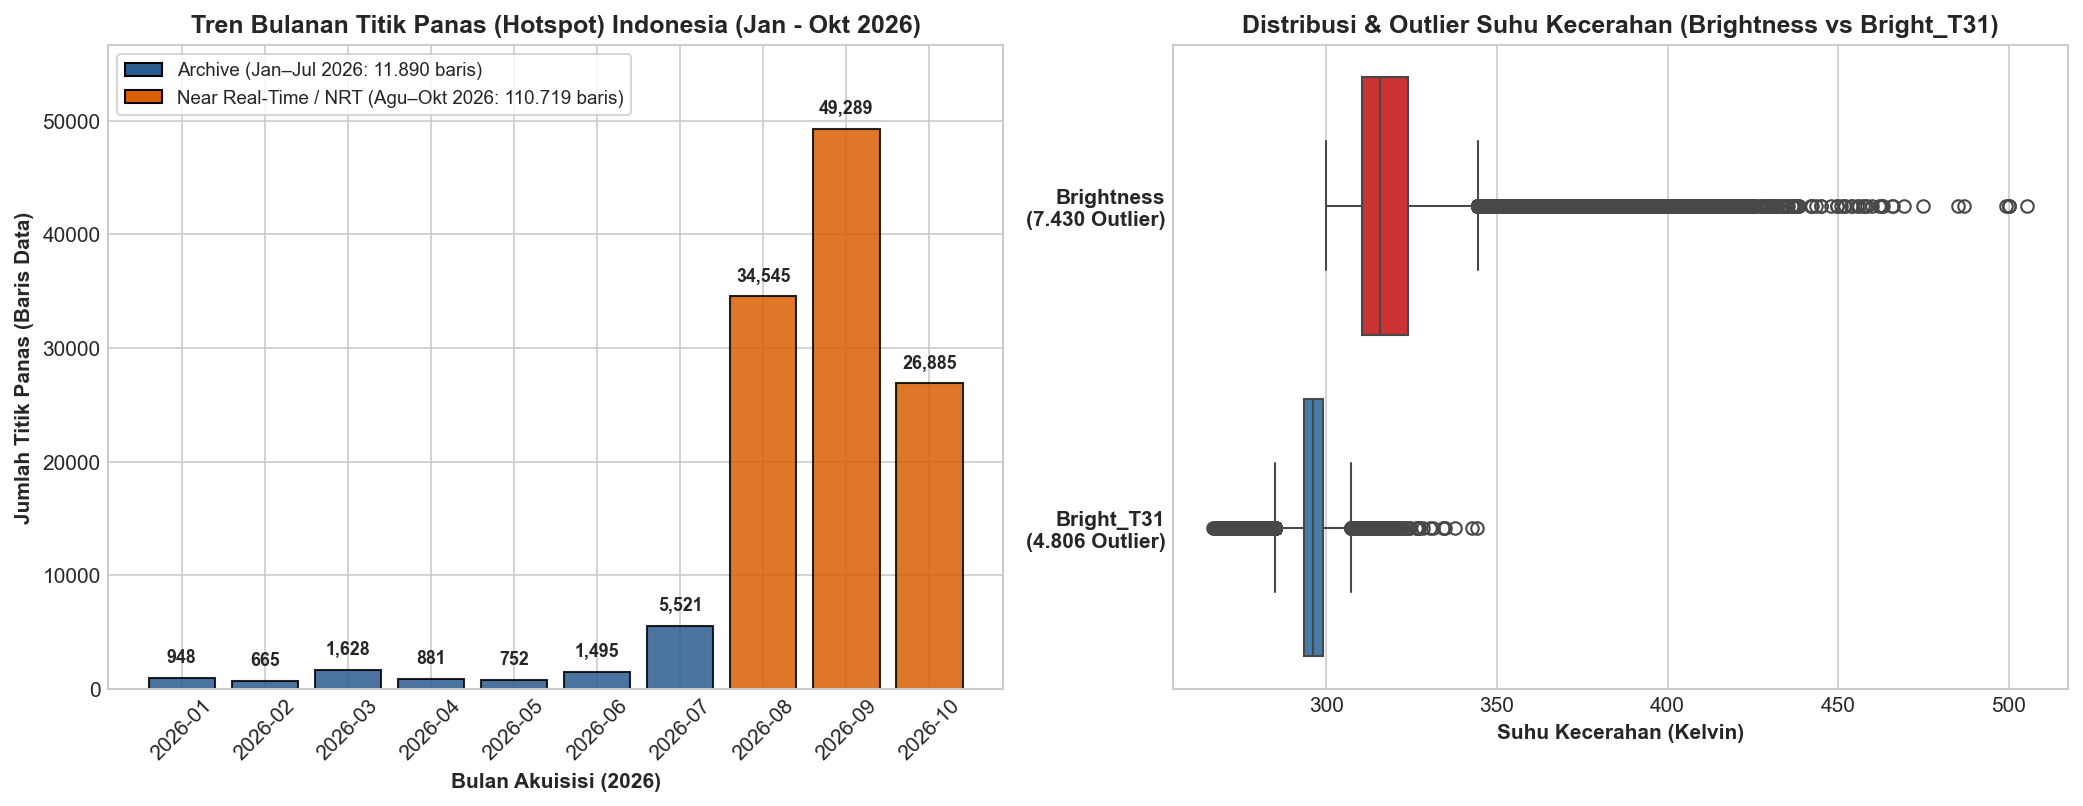

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

monthly_total = df_all.groupby('year_month').size()
colors_m = ['#2b5c8f'] * 7 + ['#d95f02'] * 3
bars = axes[0].bar(monthly_total.index, monthly_total.values, color=colors_m, edgecolor='black', alpha=0.85)
axes[0].set_title('Tren Bulanan Titik Panas (Hotspot) Indonesia (Jan - Okt 2026)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Bulan Akuisisi (2026)', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Jumlah Titik Panas (Baris Data)', fontsize=10, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

for bar in bars:
    yval = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 1000,
        f'{int(yval):,}',
        ha='center', va='bottom', fontsize=8.5, fontweight='bold'
    )
axes[0].set_ylim(0, max(monthly_total.values) * 1.15)

legend_elements = [
    Patch(facecolor='#2b5c8f', edgecolor='black', label='Archive (Jan–Jul 2026: 11.890 baris)'),
    Patch(facecolor='#d95f02', edgecolor='black', label='Near Real-Time / NRT (Agu–Okt 2026: 110.719 baris)')
]
axes[0].legend(handles=legend_elements, loc='upper left', frameon=True, facecolor='white', fontsize=9)

sns.boxplot(
    data=df_all[['brightness', 'bright_t31']],
    orient='h',
    ax=axes[1],
    palette=['#e41a1c', '#377eb8']
)
axes[1].set_title('Distribusi & Outlier Suhu Kecerahan (Brightness vs Bright_T31)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Suhu Kecerahan (Kelvin)', fontsize=10, fontweight='bold')
axes[1].set_yticklabels(['Brightness\n(7.430 Outlier)', 'Bright_T31\n(4.806 Outlier)'], fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### **Penjelasan dan Interpretasi Subbab 2.1–2.3 & Visualisasi Gambar 1 (Subbab 2.1 Penyatuan Skema & Subbab 2.3 Kualitas Data)**

1. **Penyatuan Skema & Proporsi Data *Archive* vs *Near Real-Time* (Gambar 1 — Panel Kiri | Subbab 2.1)**:
   - Penggabungan vertikal (`pd.concat`) antara berkas `fire_archive_M-C61_824794.csv` (**11.890 baris × 15 kolom**, periode **1 Januari – 31 Juli 2026**, batang biru `#2b5c8f`) dan `fire_nrt_M-C61_824794.csv` (**110.719 baris × 14 kolom**, periode **1 Agustus – 16 Oktober 2026**, batang oranye `#d95f02`) membentuk dataset terpadu `df_all` berdimensi **122.609 baris × 15 kolom**.
   - **Panel Kiri Gambar 1** memperlihatkan kesinambungan urutan waktu tanpa celah maupun tumpang-tindih (*zero overlap*) pada transisi 31 Juli ke 1 Agustus 2026, yang dikonfirmasi oleh pemeriksaan `df_all.duplicated().sum() == 0` (**0 baris duplikat**). Secara proporsional, produk **Archive menyumbang 9,70% (11.890 baris)** pada fase musim basah hingga awal transisi (948 s.d. 5.521 titik/bulan), sedangkan produk **NRT mendominasi 90,30% (110.719 baris)** akibat eskalasi karhutla musim kemarau pada Agustus (34.545 baris), September (49.289 baris), dan 1–16 Oktober (26.885 baris).
   - Pemeriksaan *missing values* membuktikan bahwa seluruh **14 atribut inti terisi 100% lengkap (`0 missing value`)**. Nilai kosong (`NaN`) hanya terdapat pada kolom `type` tepat sebanyak **110.719 baris (90,30%)** milik segmen NRT. Kondisi ini bersifat *missing by design* (struktural operasional NASA FIRMS) karena atribusi sumber panas (`type`) baru dihitung ketika data NRT diproses ulang menjadi produk *Standard Science Quality Archive*. Oleh sebab itu, atribut `type` tidak dijadikan fitur prediktor model (menghindari *data leakage* skema NRT vs *Archive*), melainkan dimanfaatkan khusus untuk audit representativitas ekologis pada Subbab 2.5.

2. **Evaluasi Statistik Deskriptif & Deteksi *Outlier* Suhu Kecerahan `1.5 * IQR` (Gambar 1 — Panel Kanan | Subbab 2.3)**:
   - **Panel Kanan Gambar 1** memvisualisasikan perbandingan sebaran kuartil dan pencilan (*outlier* metode pagar dalam $Q_1 - 1,5 \times \text{IQR}$ dan $Q_3 + 1,5 \times \text{IQR}$) antara dua kanal inframerah termal utama MODIS:
     - **`Brightness` (Kanal 21/22, ~3,96 µm — merah `#e41a1c`)**: Memiliki median **315,65 K** (mean **319,34 K**, std **14,72 K**) dengan **7.430 *outlier* (6,06%)** yang seluruhnya menjulur panjang ke ekor kanan (*unilateral right-skewed*) hingga mencapai suhu maksimum **505,50 K**.
     - **`Bright_T31` (Kanal 31, ~11,0 µm — biru `#377eb8`)**: Memiliki distribusi jauh lebih rapat di sekitar suhu latar permukaan bumi (median **295,95 K**, mean **295,72 K**, std **5,06 K**) dengan **4.806 *outlier* (3,92%)** yang tersebar di kedua sisi kumis (*bilateral outliers*, rentang **266,86 K – 344,02 K**)—di mana ekor kiri merepresentasikan piksel dingin yang terkontaminasi tepi awan tinggi, sedangkan ekor kanan merepresentasikan pemanasan radiasi permukaan ekstrem atau rambatan panas kebakaran besar.
   - Selain kedua kanal suhu tersebut, tabel evaluasi `1.5 * IQR` juga mencatat pencilan signifikan pada **`frp` (11.932 *outlier* | 9,73%; maks 2.488,53 MW)** serta geometri piksel tepi sapuan **`scan` (12.239 *outlier*)** dan **`track` (9.440 *outlier*)**. Dalam domain penginderaan jauh kebakaran aktif, *outlier* ekstrem atas pada `brightness`, `bright_t31`, dan `frp` **bukanlah kesalahan sensor (*noise/error*)**, melainkan **sinyal fisik kebakaran hebat (*high-intensity wildfire*)** yang justru menjadi target prioritas utama verifikasi lapangan, sehingga seluruh baris data wajib dipertahankan utuh ($N = 122.609$).

3. **Pembentukan Periode Bulanan & Diskritisasi Variabel Target (`conf_cat`)**:
   - Atribut tanggal `acq_date` dikonversi ke tipe `datetime` (`acq_date_dt`) untuk mengekstrak indeks agregasi bulanan `year_month`, sementara skor kontinu `confidence` (0–100%) didiskritisasi mengacu ambang baku *MODIS Collection 6.1* ke dalam tiga kelas target: **`Low (<30%)`** sebanyak **7.198 baris (5,87%)**, **`Nominal (30%–79%)`** sebanyak **76.021 baris (62,00%)**, dan **`High (80%–100%)`** sebanyak **39.390 baris (32,13%)**.

---
### **2.4 *Exploratory Data Analysis* (EDA) Berinsight**

Tahap eksplorasi data dilakukan untuk menggali pola empiris yang mendasari perancangan pra-pemrosesan, rekayasa fitur, dan strategi pemodelan klasifikasi penyaringan prioritas verifikasi lapangan.

### **2.4.1 Analisis Distribusi Kelas Target dan Anomali Waktu Kejadian (Siang vs Malam)**

Sel berikut membuat dua panel: **(A)** distribusi jumlah dan persentase tiap kelas `conf_cat`, serta **(B)** *grouped bar chart* hasil `pd.crosstab` antara `conf_cat` dan `daynight` untuk membandingkan deteksi siang dan malam pada setiap kelas.

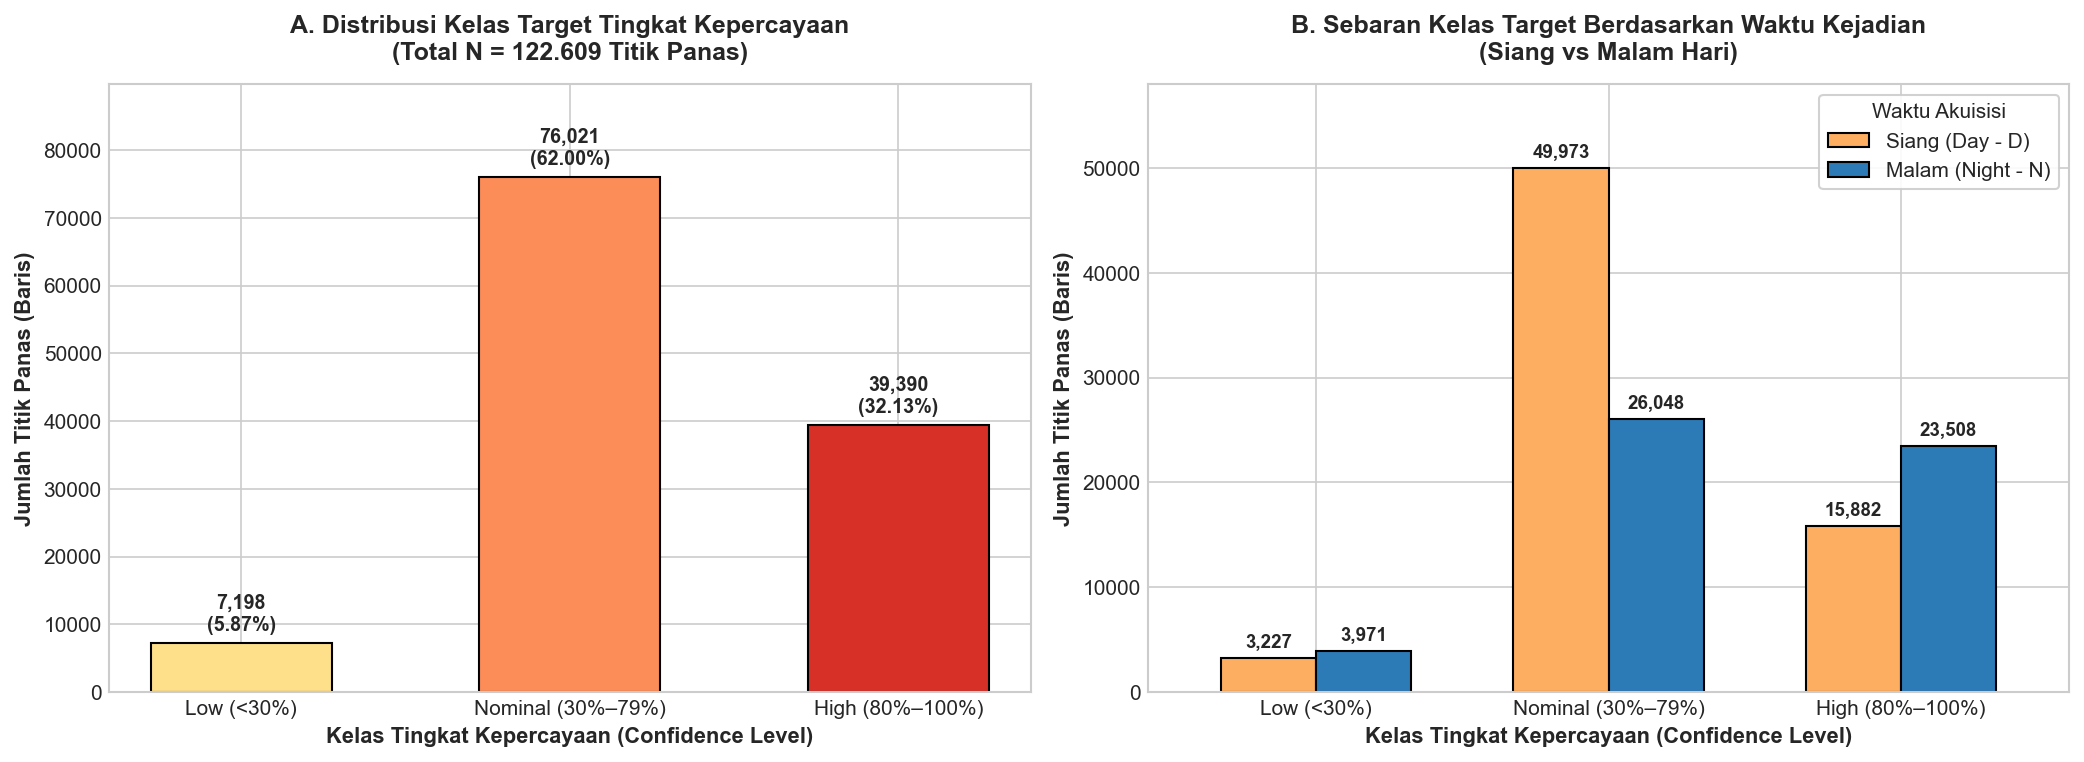

Agregat Populasi -> Siang (D): 69,082 (56.34%) | Malam (N): 53,527 (43.66%)
Proporsi Malam pada Kelas High Confidence: 23,508 dari 39,390 titik (59.68%)

In [6]:
palette_cls = ['#fee08b', '#fc8d59', '#d73027']
class_order = ['Low (<30%)', 'Nominal (30%–79%)', 'High (80%–100%)']

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

conf_counts = df_all['conf_cat'].value_counts().reindex(class_order)
total_n = len(df_all)

bars_a = axes[0].bar(
    conf_counts.index.astype(str),
    conf_counts.values,
    color=palette_cls,
    edgecolor='black',
    width=0.55
)
axes[0].set_title(
    'A. Distribusi Kelas Target Tingkat Kepercayaan\n(Total N = 122.609 Titik Panas)',
    fontsize=12, fontweight='bold', pad=12
)
axes[0].set_xlabel('Kelas Tingkat Kepercayaan (Confidence Level)', fontsize=10.5, fontweight='bold')
axes[0].set_ylabel('Jumlah Titik Panas (Baris)', fontsize=10.5, fontweight='bold')
axes[0].set_ylim(0, conf_counts.max() * 1.18)

for bar, count in zip(bars_a, conf_counts.values):
    pct = count / total_n * 100
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1300,
        f"{count:,}\n({pct:.2f}%)",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold'
    )

ct_daynight = pd.crosstab(df_all['conf_cat'], df_all['daynight']).reindex(class_order)[['D', 'N']]
ct_daynight.columns = ['Siang (Day - D)', 'Malam (Night - N)']

ct_daynight.plot(
    kind='bar',
    ax=axes[1],
    color=['#fdae61', '#2c7bb6'],
    edgecolor='black',
    width=0.65
)
axes[1].set_title(
    'B. Sebaran Kelas Target Berdasarkan Waktu Kejadian\n(Siang vs Malam Hari)',
    fontsize=12, fontweight='bold', pad=12
)
axes[1].set_xlabel('Kelas Tingkat Kepercayaan (Confidence Level)', fontsize=10.5, fontweight='bold')
axes[1].set_ylabel('Jumlah Titik Panas (Baris)', fontsize=10.5, fontweight='bold')
axes[1].tick_params(axis='x', rotation=0)
axes[1].set_ylim(0, ct_daynight.values.max() * 1.16)
axes[1].legend(title='Waktu Akuisisi', frameon=True, facecolor='white', framealpha=0.9)

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        labels=[f"{int(v):,}" for v in container.datavalues],
        padding=3,
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

day_total = (df_all['daynight'] == 'D').sum()
night_total = (df_all['daynight'] == 'N').sum()
high_night_pct = ct_daynight.loc['High (80%–100%)', 'Malam (Night - N)'] / conf_counts['High (80%–100%)'] * 100
print(f"Agregat Populasi -> Siang (D): {day_total:,} ({day_total/total_n*100:.2f}%) | Malam (N): {night_total:,} ({night_total/total_n*100:.2f}%)")
print(f"Proporsi Malam pada Kelas High Confidence: {ct_daynight.loc['High (80%–100%)', 'Malam (Night - N)']:,} dari {conf_counts['High (80%–100%)']:,} titik ({high_night_pct:.2f}%)")

#### **Penjelasan dan Interpretasi Insight Visualisasi 2.4.1**

1. **Ketimpangan Kelas (*Class Imbalance*) yang Signifikan (Panel A)**:
   Distribusi populasi dari total **122.609 titik panas** didominasi secara kuat oleh kelas **`Nominal (30%–79%)`** sebanyak **76.021 titik (62,00%)**, disusul oleh kelas prioritas utama **`High (80%–100%)`** sebanyak **39.390 titik (32,13%)**, sedangkan kelas **`Low (<30%)`** merupakan kelas minoritas ekstrem yang hanya mencakup **7.198 titik (5,87%)** (rasio ketimpangan lebih dari **10,5 : 1** antara kelas *Nominal* terhadap *Low*). Temuan ini membawa tiga konsekuensi metodologis wajib pada tahap pemodelan:
   - Pembagian data latih dan uji wajib menggunakan ***Stratified Train-Test Split*** agar proporsi ketiga kelas terjaga identik dan kelas minoritas *Low* tidak tereduksi pada salah satu partisi.
   - Algoritma klasifikasi perlu menerapkan pembobotan penalti kesalahan **`class_weight='balanced'`** agar fungsi objektif model tidak bias menebak kelas mayoritas (*Nominal*).
   - Penggunaan metrik *Accuracy* semata akan menyesatkan, sehingga evaluasi model wajib berfokus pada ***Macro F1-Score*** (menilai kinerja setara lintas ketiga kelas) serta ***Recall* Kelas *High*** guna meminimalkan risiko *false negative* (titik api berkepercayaan tinggi yang gagal diprioritaskan ke tim patroli lapangan).

2. **Anomali *Nocturnal Hotspot* pada Kelas *High Confidence* (Panel B)**:
   Secara agregat di seluruh dataset, deteksi pada **siang hari (*Day - D*)** tercatat lebih banyak yakni **69.082 titik (56,34%)** dibandingkan **malam hari (*Night - N*)** sebanyak **53.527 titik (43,66%)**, yang terutama disumbang oleh kelas *Nominal* di siang hari (49.973 titik vs 26.048 titik di malam hari). Namun, terjadi pembalikan pola (*crossover anomaly*) yang sangat tajam pada kelas **`High (80%–100%)`**: sebanyak **23.508 dari 39.390 titik (59,68%)** justru terdeteksi pada **malam hari**, melampaui deteksi siang hari yang hanya 15.882 titik (40,32%). Secara fisika penginderaan jauh, fenomena *nocturnal hotspot* ini terjadi karena pada malam hari tidak terdapat gangguan pantulan radiasi gelombang pendek matahari (*solar reflection / sun glint*) dan suhu latar permukaan daratan mendingin secara merata, sehingga kontras pancaran termal api terhadap piksel tetangga meningkat tajam dan algoritma kontekstual MODIS memberikan skor kepercayaan (*confidence*) yang jauh lebih tinggi tanpa penalti ambang siang hari. Hal ini membuktikan bahwa atribut waktu kejadian (`daynight` dan `acq_time`) merupakan prediktor kontekstual yang krusial dalam interaksi dengan suhu termal.

---
### **2.4.2 Analisis Tren Jumlah Deteksi Titik Panas per Bulan (Januari–Oktober 2026)**

Sel berikut menghitung jumlah titik panas per `year_month`, menampilkannya sebagai *bar chart* (biru = *Archive*, oranye = NRT) dengan garis tren putus-putus, lalu mencetak ringkasan angka musiman pendukung narasi.

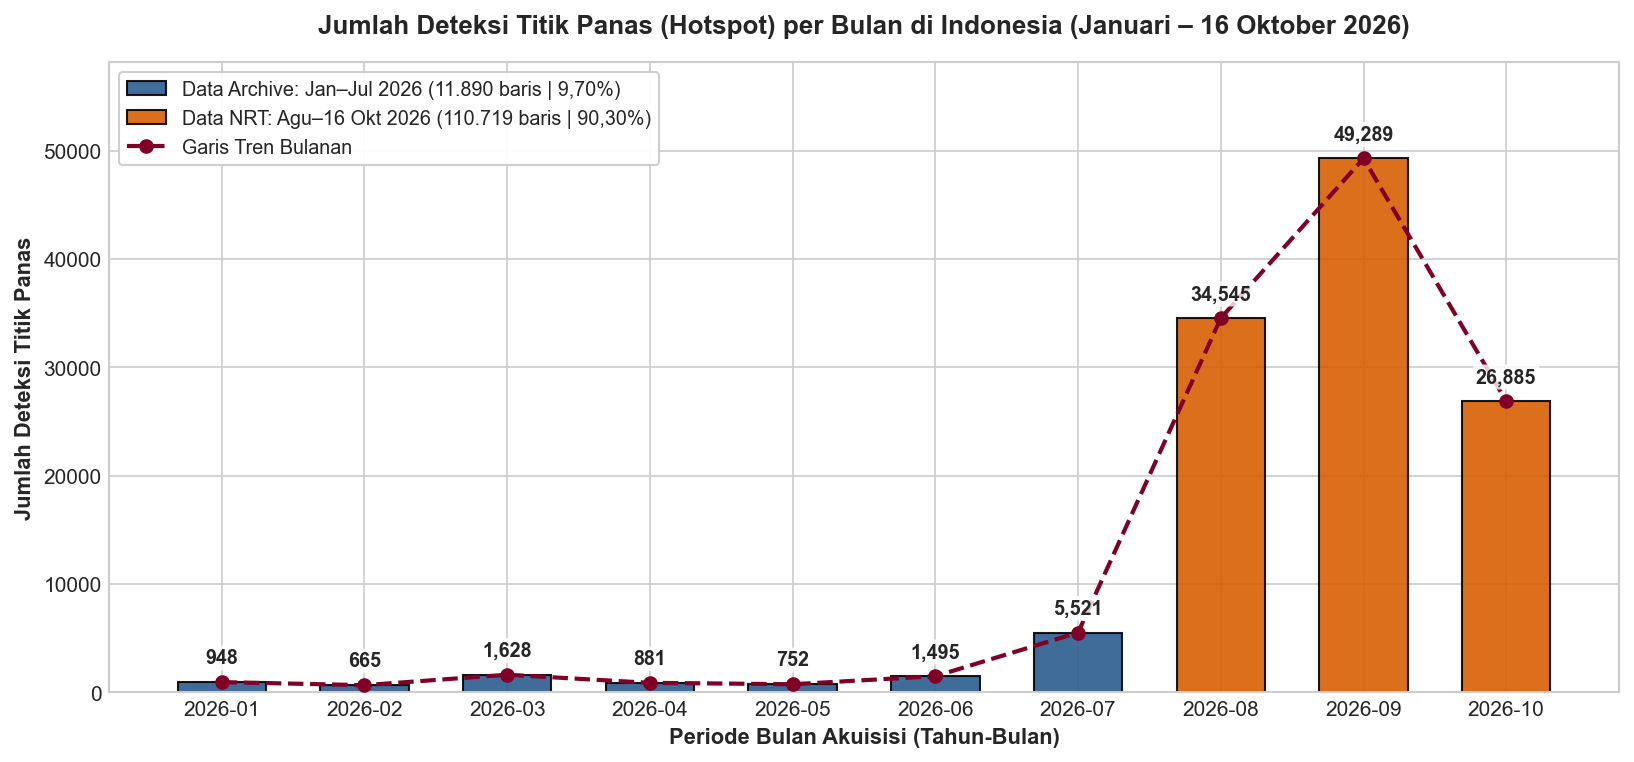

Total Jan–Jun 2026 (6 bulan basah)     : 6,369 titik (rentang 665 – 1,628 titik/bulan)
Transisi Juli 2026                     : 5,521 titik
Proporsi Lonjakan NRT thd Archive      : 931.19% (110.719 vs 11.890 titik)
Puncak September 2026                  : 49,289 titik (40.20% dari total populasi)
Laju Harian 1–16 Oktober 2026          : 26,885 titik / 16 hari = 1,680 titik/hari

In [7]:
monthly_counts = df_all['year_month'].value_counts().sort_index()

bar_colors = ['#2b5c8f'] * 7 + ['#d95f02'] * 3

fig, ax = plt.subplots(figsize=(11, 5.2))

bars = ax.bar(
    monthly_counts.index,
    monthly_counts.values,
    color=bar_colors,
    edgecolor='black',
    width=0.62,
    alpha=0.9,
    zorder=2
)

ax.plot(
    range(len(monthly_counts)),
    monthly_counts.values,
    color='#800026',
    marker='o',
    linewidth=2,
    linestyle='--',
    zorder=3
)

ax.set_title(
    'Jumlah Deteksi Titik Panas (Hotspot) per Bulan di Indonesia (Januari – 16 Oktober 2026)',
    fontsize=12.5, fontweight='bold', pad=14
)
ax.set_xlabel('Periode Bulan Akuisisi (Tahun-Bulan)', fontsize=10.5, fontweight='bold')
ax.set_ylabel('Jumlah Deteksi Titik Panas', fontsize=10.5, fontweight='bold')
ax.set_ylim(0, monthly_counts.max() * 1.18)

for bar, val in zip(bars, monthly_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1350,
        f"{val:,}",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8),
        zorder=4
    )

arc_label_str = f"Data Archive: Jan–Jul 2026 ({len(df_arc):,}".replace(',', '.') + f" baris | {len(df_arc)/len(df_all)*100:.2f}%)".replace('.', ',')
nrt_label_str = f"Data NRT: Agu–16 Okt 2026 ({len(df_nrt):,}".replace(',', '.') + f" baris | {len(df_nrt)/len(df_all)*100:.2f}%)".replace('.', ',')

legend_elements = [
    Patch(facecolor='#2b5c8f', edgecolor='black', alpha=0.9, label=arc_label_str),
    Patch(facecolor='#d95f02', edgecolor='black', alpha=0.9, label=nrt_label_str),
    plt.Line2D([0], [0], color='#800026', marker='o', linewidth=2, linestyle='--', label='Garis Tren Bulanan')
]
ax.legend(handles=legend_elements, loc='upper left', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.5)

plt.tight_layout()
plt.show()

jan_jun_sum = monthly_counts.loc['2026-01':'2026-06'].sum()
sep_pct = monthly_counts.loc['2026-09'] / len(df_all) * 100
oct_daily_rate = monthly_counts.loc['2026-10'] / 16
ratio_nrt_arc_pct = (len(df_nrt) / len(df_arc)) * 100
print(f"Total Jan–Jun 2026 (6 bulan basah)     : {jan_jun_sum:,} titik (rentang {monthly_counts.loc['2026-01':'2026-06'].min():,} – {monthly_counts.loc['2026-01':'2026-06'].max():,} titik/bulan)")
print(f"Transisi Juli 2026                     : {monthly_counts.loc['2026-07']:,} titik")
print(f"Proporsi Lonjakan NRT thd Archive      : {ratio_nrt_arc_pct:.2f}% (110.719 vs 11.890 titik)")
print(f"Puncak September 2026                  : {monthly_counts.loc['2026-09']:,} titik ({sep_pct:.2f}% dari total populasi)")
print(f"Laju Harian 1–16 Oktober 2026          : {monthly_counts.loc['2026-10']:,} titik / 16 hari = {oct_daily_rate:,.0f} titik/hari")

#### **Penjelasan dan Interpretasi Insight Visualisasi 2.4.2**

1. **Pola Musiman (*Seasonality*) Ekstrem Iklim Monsun Indonesia**:
   Distribusi temporal memperlihatkan kontras musiman yang sangat tajam antara paruh awal tahun yang basah dan puncak musim kemarau. Sepanjang periode penghujan hingga peralihan awal **Januari–Juni 2026**, aktivitas titik panas sangat rendah dengan akumulasi hanya **6.369 titik** selama enam bulan penuh (berfluktuasi antara **665 hingga 1.628 titik/bulan**, dengan titik terendah pada Februari sebanyak 665 titik). Memasuki awal kemarau pada **Juli 2026**, deteksi mulai merangkak naik signifikan menjadi **5.521 titik** (hampir menyamai total gabungan enam bulan sebelumnya), sehingga keseluruhan periode Data *Archive* (Jan–Jul 2026) menyumbang **11.890 baris (9,70%)**.

2. **Ledakan Eksponensial Periode Kemarau Agustus–Oktober 2026**:
   Memasuki puncak kemarau pada periode Data *Near Real-Time* (**1 Agustus – 16 Oktober 2026**), volume titik panas melonjak sebesar **931,19%** terhadap total periode *Archive* hingga mencapai **110.719 baris (90,30%)**:
   - **Agustus 2026** langsung melesat lebih dari 6 kali lipat dari Juli menjadi **34.545 titik**.
   - **September 2026** menjadi puncak eskalasi tertinggi dengan **49.289 titik**, yang berarti **40,20%** dari seluruh populasi titik panas Indonesia sepanjang 2026 terkonsentrasi hanya dalam satu bulan tersebut.
   - **1–16 Oktober 2026** mencatat **26.885 titik** hanya dalam rentang **16 hari pengamatan**, yang merepresentasikan laju deteksi rata-rata ekstrem sebesar **~1.680 titik panas per hari** (bila berlanjut satu bulan penuh berpotensi menembus >50.000 titik).

3. **Relevansi Operasional bagi Penyaringan Prioritas Lapangan**:
   Ketika laju kemunculan mencapai ribuan titik panas per hari pada bulan Agustus–Oktober, kapasitas personel Manggala Agni, BPBD, dan TNI/Polri tidak mungkin melakukan pengecekan darat (*groundcheck*) terhadap seluruh koordinat secara serentak. Oleh karena itu, model klasifikasi prediktif yang mampu menyaring titik berkepercayaan tinggi (*High Confidence*) secara otomatis pada aliran data NRT sangat dibutuhkan untuk mencegah keterlambatan pemadaman pada fase kritis musim kemarau.

---
### **2.4.3 Analisis Distribusi Fitur Termal Melalui Histogram dan Boxplot**

Sel berikut membuat empat panel: **(A)** histogram tumpang-tindih `brightness` vs `bright_t31`, **(B)** histogram `frp` pada skala `log1p`, **(C)** boxplot `brightness` per kelas, dan **(D)** boxplot `frp` per kelas (tanpa *fliers*), diikuti tabel agregasi `mean` dan `median` per kelas target.

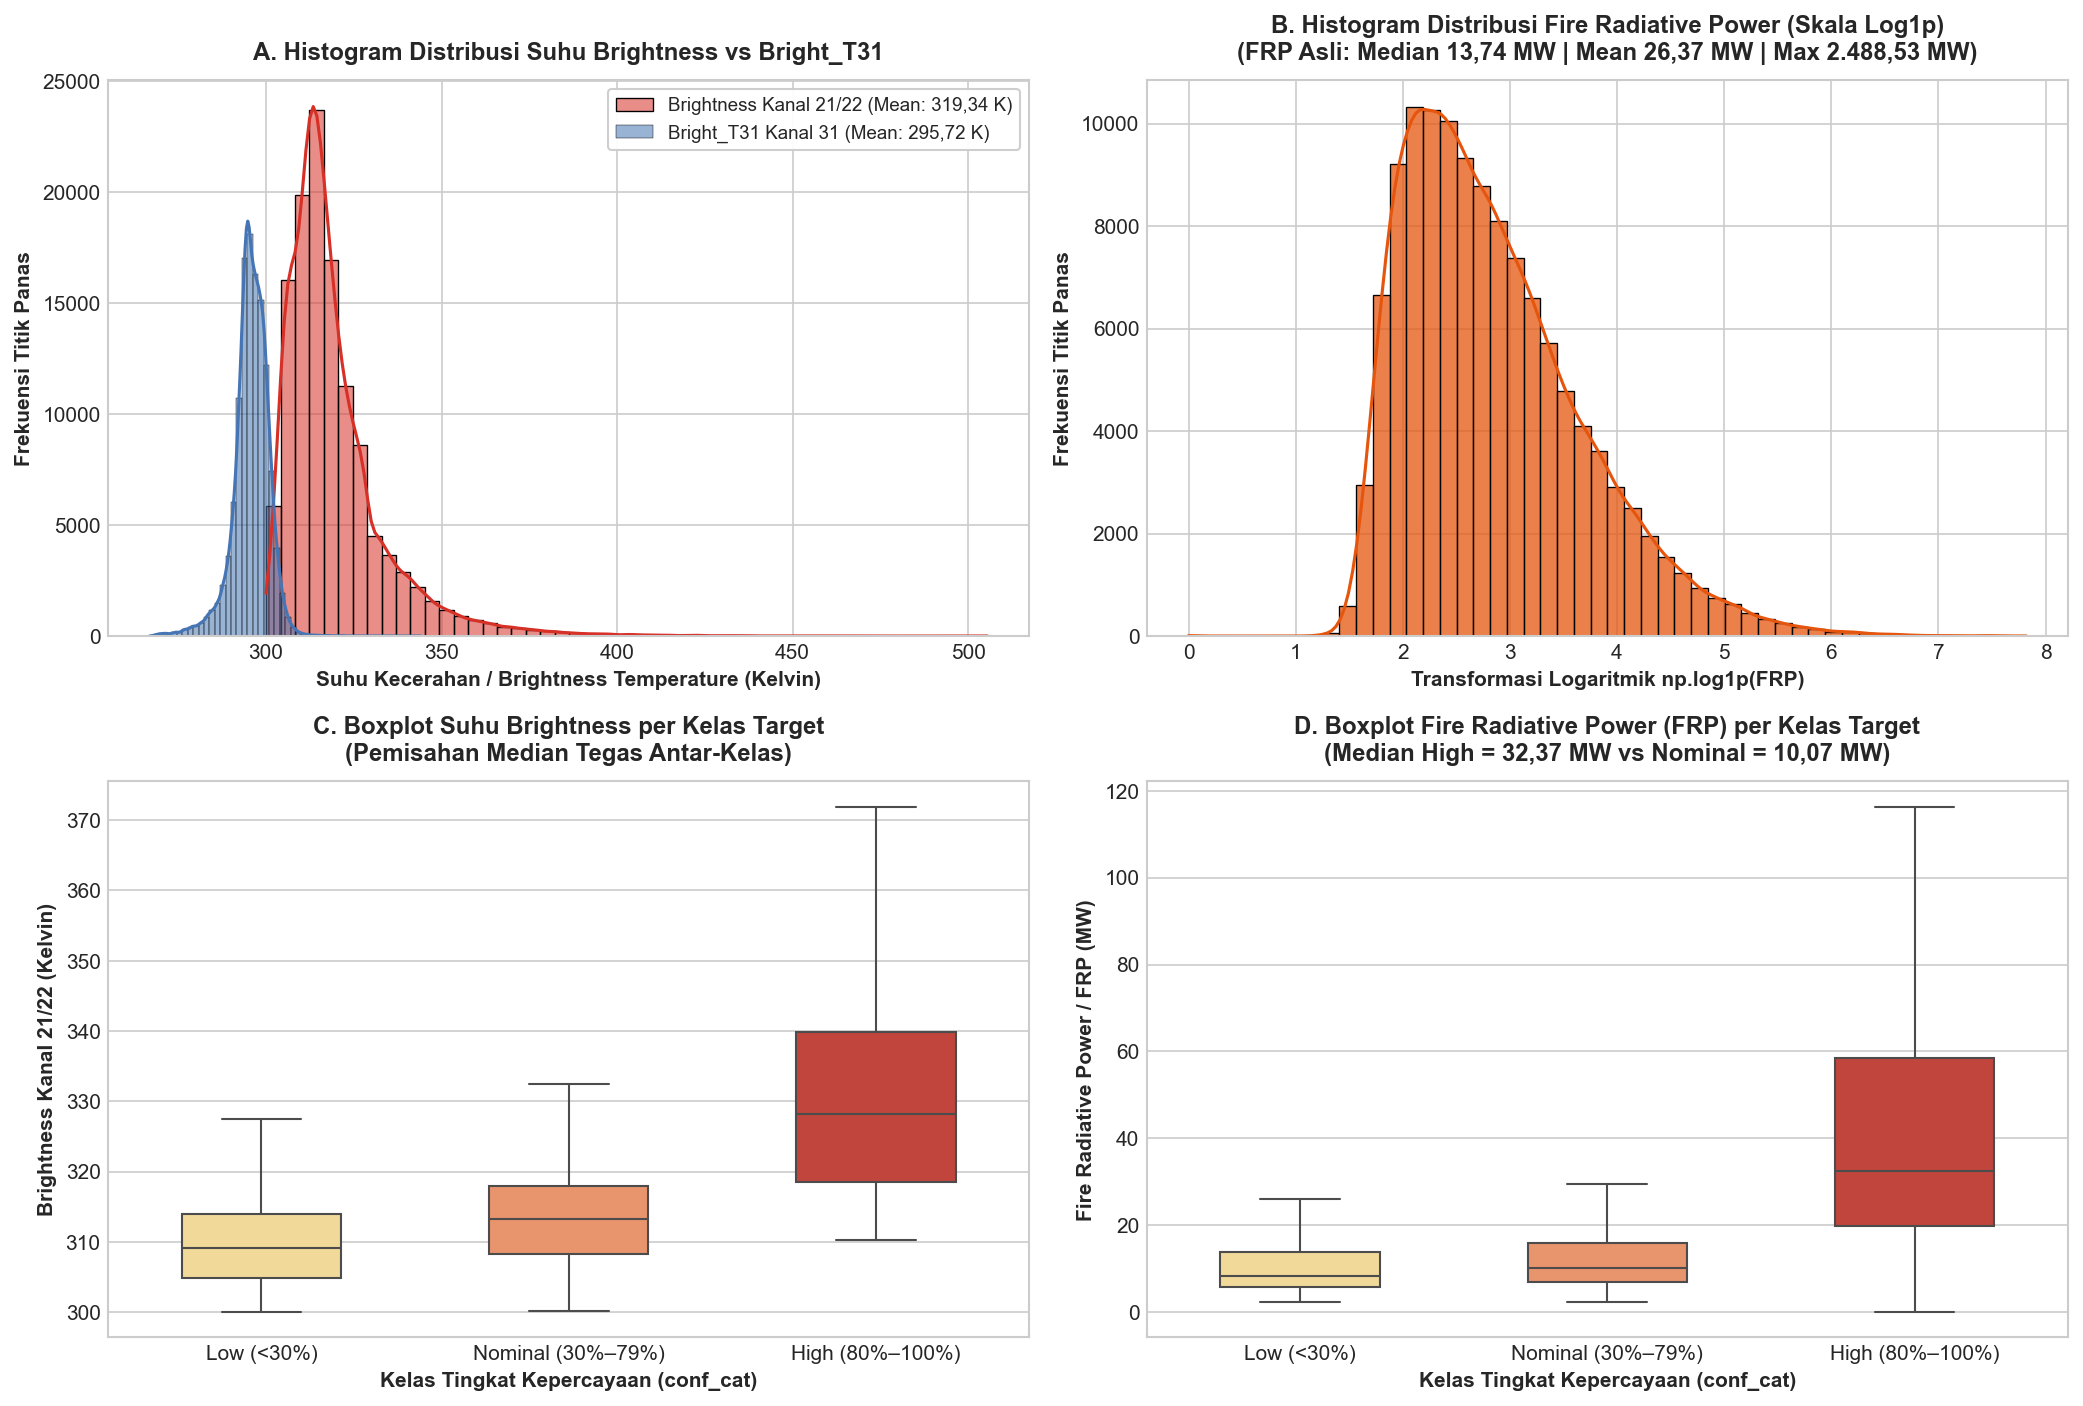

=== TABEL AGREGASI FITUR TERMAL & UKURAN PIKSEL PER KELAS TARGET ===

brightness        bright_t31          frp          scan       
                        mean median       mean median  mean median   mean median
conf_cat                                                                        
Low (<30%)            310.17 309.15     293.27 294.07 12.52 8.2200 1.5100 1.2000
Nominal (30%–79%)     313.66 313.19     295.66 296.06 13.72  10.07 1.3900 1.1500
High (80%–100%)       331.98 328.13     296.28 296.09 53.29  32.37 1.3600 1.1400

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

sns.histplot(
    df_all['brightness'], bins=50, kde=True, color='#d73027', alpha=0.55,
    label='Brightness Kanal 21/22 (Mean: 319,34 K)',
    ax=axes[0, 0]
)
sns.histplot(
    df_all['bright_t31'], bins=50, kde=True, color='#4575b4', alpha=0.55,
    label='Bright_T31 Kanal 31 (Mean: 295,72 K)',
    ax=axes[0, 0]
)
axes[0, 0].set_title('A. Histogram Distribusi Suhu Brightness vs Bright_T31', fontsize=11.5, fontweight='bold', pad=10)
axes[0, 0].set_xlabel('Suhu Kecerahan / Brightness Temperature (Kelvin)', fontsize=10, fontweight='bold')
axes[0, 0].set_ylabel('Frekuensi Titik Panas', fontsize=10, fontweight='bold')
axes[0, 0].legend(frameon=True, facecolor='white', framealpha=0.95, fontsize=9)

sns.histplot(
    np.log1p(df_all['frp']), bins=50, kde=True, color='#e6550d', alpha=0.75,
    ax=axes[0, 1]
)
axes[0, 1].set_title(
    'B. Histogram Distribusi Fire Radiative Power (Skala Log1p)\n'
    '(FRP Asli: Median 13,74 MW | Mean 26,37 MW | Max 2.488,53 MW)',
    fontsize=11.5, fontweight='bold', pad=10
)
axes[0, 1].set_xlabel('Transformasi Logaritmik np.log1p(FRP)', fontsize=10, fontweight='bold')
axes[0, 1].set_ylabel('Frekuensi Titik Panas', fontsize=10, fontweight='bold')

sns.boxplot(
    data=df_all, x='conf_cat', y='brightness', hue='conf_cat',
    palette=palette_cls, showfliers=False, legend=False, width=0.52,
    ax=axes[1, 0]
)
axes[1, 0].set_title(
    'C. Boxplot Suhu Brightness per Kelas Target\n(Pemisahan Median Tegas Antar-Kelas)',
    fontsize=11.5, fontweight='bold', pad=10
)
axes[1, 0].set_xlabel('Kelas Tingkat Kepercayaan (conf_cat)', fontsize=10, fontweight='bold')
axes[1, 0].set_ylabel('Brightness Kanal 21/22 (Kelvin)', fontsize=10, fontweight='bold')

sns.boxplot(
    data=df_all, x='conf_cat', y='frp', hue='conf_cat',
    palette=palette_cls, showfliers=False, legend=False, width=0.52,
    ax=axes[1, 1]
)
axes[1, 1].set_title(
    'D. Boxplot Fire Radiative Power (FRP) per Kelas Target\n(Median High = 32,37 MW vs Nominal = 10,07 MW)',
    fontsize=11.5, fontweight='bold', pad=10
)
axes[1, 1].set_xlabel('Kelas Tingkat Kepercayaan (conf_cat)', fontsize=10, fontweight='bold')
axes[1, 1].set_ylabel('Fire Radiative Power / FRP (MW)', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

print("=== TABEL AGREGASI FITUR TERMAL & UKURAN PIKSEL PER KELAS TARGET ===")
agg_thermal = df_all.groupby('conf_cat', observed=False)[['brightness', 'bright_t31', 'frp', 'scan']].agg(['mean', 'median']).round(2)
display(agg_thermal)

#### **Penjelasan dan Interpretasi Insight Visualisasi 2.4.3**

1. **Karakteristik Kecondongan Kanan (*Right-Skewed*) dan Normalisasi `log1p` (Panel A & Panel B)**:
   - Pada **Panel A**, distribusi suhu kanal latar inframerah termal gelombang panjang **`bright_t31`** (Kanal 31, ~11 µm) terpusat rapat dan relatif simetris di sekitar suhu permukaan bumi tropis (**Mean: 295,72 K | Median: 295,95 K**). Sebaliknya, suhu kanal deteksi api aktif **`brightness`** (Kanal 21/22 *mid-infrared*, ~3,96 µm) bergeser jauh ke kanan (**Mean: 319,34 K | Median: 315,65 K**) dengan ekor kanan panjang (*right-skewed*) yang mencapai maksimum **505,50 K** serta memuat **7.430 *outlier***.
   - Pada atribut daya pancar radiasi api **`frp` (*Fire Radiative Power*)**, kecondongan kanan jauh lebih ekstrem lagi dengan **11.932 *outlier***: nilai median berada di **13,74 MW**, rata-rata tertarik naik menjadi **26,37 MW**, dan nilai maksimum menembus **2.488,53 MW**. Sebagaimana ditunjukkan pada **Panel B**, penerapan transformasi logaritmik **`np.log1p(frp)`** berhasil memampatkan rentang ekor ekstrem tersebut menjadi distribusi lonceng (*bell-shaped* mendekati normal) tanpa mengeliminasi satu pun observasi kebakaran besar. Transformasi ini sangat menguntungkan bagi stabilitas gradien dan skala jarak pada algoritma klasifikasi non-pohon (seperti *Logistic Regression*, *SVM*, atau *KNN*).

2. **Daya Pisah Kuartil (*Interquartile Separability*) Antar-Kelas Target (Panel C, Panel D, & Tabel Agregasi)**:
   - **Panel C (`brightness` per kelas)** memperlihatkan kenaikan nilai tengah dan rentang antarkuartil (IQR) yang berjenjang tegas seiring naiknya kelas kepercayaan: median `brightness` meningkat dari **`Low` (309,15 K; mean 310,17 K)** → **`Nominal` (313,19 K; mean 313,66 K)** → melonjak tajam pada kelas **`High` (328,13 K; mean 331,98 K)**. Bahkan kuartil bawah ($Q_1$) kelas *High* sudah berada di atas kuartil atas ($Q_3$) kelas *Nominal*, mengindikasikan daya pisah univariat yang sangat kuat.
   - **Panel D (`frp` per kelas)** mengonfirmasi pemisahan energi pancaran api yang mencolok: median `frp` pada kelas **`High` mencapai 32,37 MW (mean 53,29 MW)**—lebih dari **3 kali lipat** dibandingkan median kelas **`Nominal` (10,07 MW; mean 13,72 MW)** dan hampir **4 kali lipat** kelas **`Low` (8,22 MW; mean 12,52 MW)**. Sementara itu, suhu latar `bright_t31` relatif stabil lintas kelas (median 294,07 K – 296,09 K), menunjukkan bahwa penentu utama naiknya kelas kepercayaan bukan tingginya suhu latar daratan, melainkan besarnya **selisih/anomali suhu titik api di atas suhu latarnya**.

---
### **2.4.4 Analisis Heatmap Korelasi Antar-Fitur Numerik**

Sel berikut menghitung matriks korelasi Pearson antar-9 fitur numerik dan menampilkannya sebagai *heatmap* beranotasi dengan skala warna `RdBu_r` (−1 hingga 1).

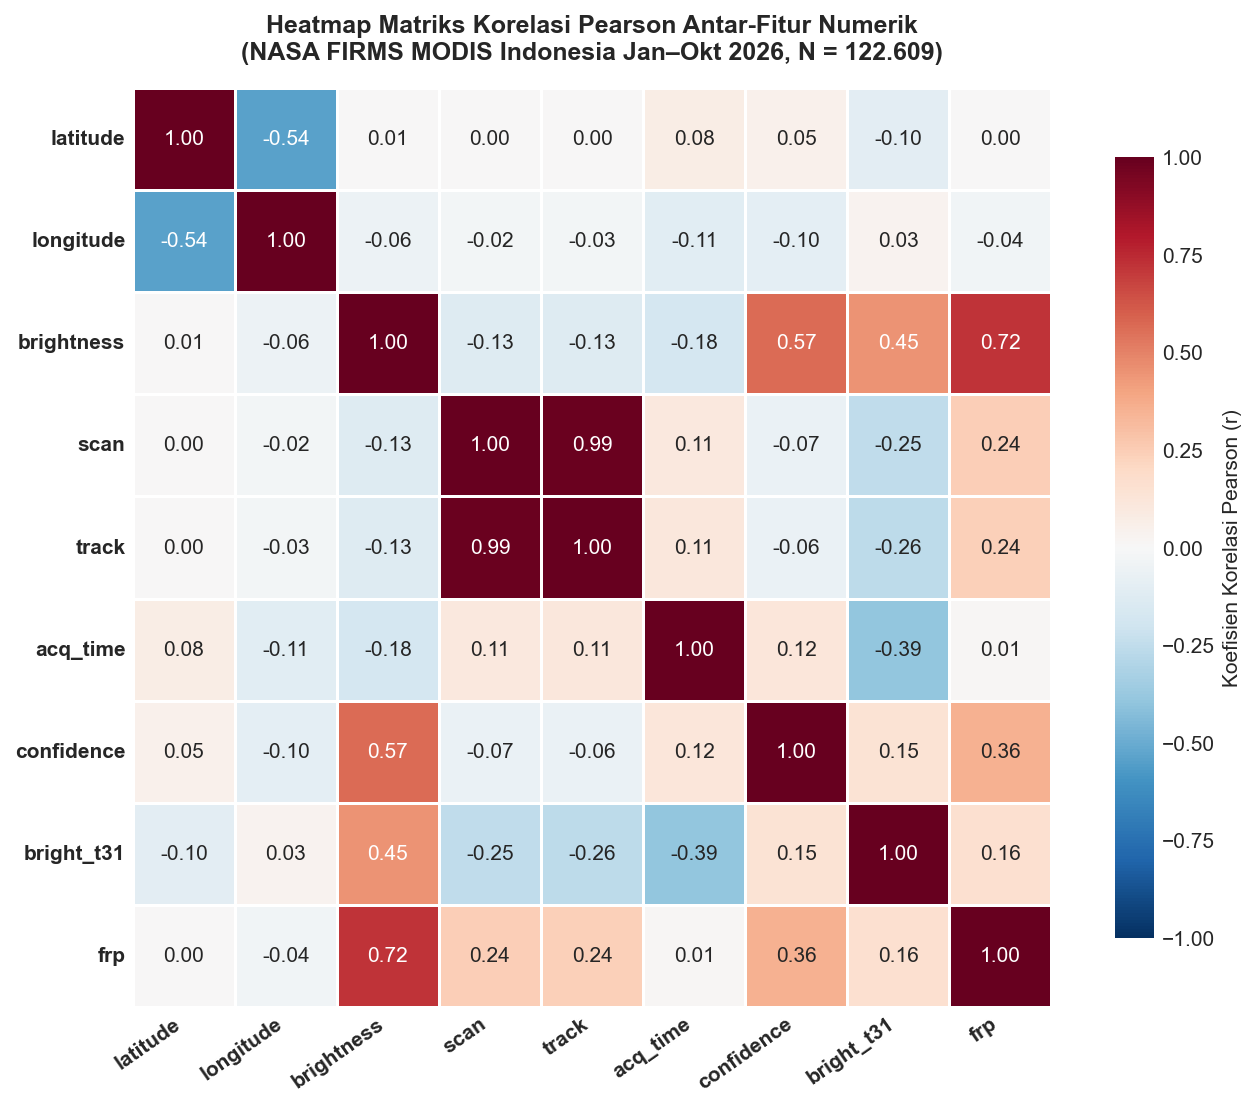

Korelasi presisi tinggi scan vs track       : r = 0.9885
Korelasi presisi tinggi acq_time vs bright_t31 : r = -0.3949

In [9]:
corr_matrix = df_all[num_cols].corr()

fig, ax = plt.subplots(figsize=(9.5, 7.5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={'shrink': 0.85, 'label': 'Koefisien Korelasi Pearson (r)'},
    ax=ax
)

ax.set_title(
    'Heatmap Matriks Korelasi Pearson Antar-Fitur Numerik\n'
    '(NASA FIRMS MODIS Indonesia Jan–Okt 2026, N = 122.609)',
    fontsize=12, fontweight='bold', pad=14
)
plt.xticks(rotation=35, ha='right', fontweight='bold')
plt.yticks(rotation=0, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Korelasi presisi tinggi scan vs track       : r = {corr_matrix.loc['scan', 'track']:.4f}")
print(f"Korelasi presisi tinggi acq_time vs bright_t31 : r = {corr_matrix.loc['acq_time', 'bright_t31']:.4f}")

#### **Penjelasan dan Interpretasi Insight Visualisasi 2.4.4**

Berdasarkan matriks korelasi linear Pearson pada 122.609 titik panas di atas, diperoleh **empat *insight* utama** yang menjadi landasan langsung bagi tahap *Feature Selection* dan *Feature Engineering*:

1. **Korelasi Positif Kuat `brightness` terhadap `confidence` ($r = 0,57$) dan `frp` ($r = 0,72$)**:
   `brightness` merupakan fitur tunggal dengan hubungan linear terkuat terhadap skor target `confidence` ($r = 0,57$), diikuti oleh `frp` terhadap `confidence` ($r = 0,36$). Selain itu, `brightness` berkorelasi kuat dengan `frp` ($r = 0,72$) karena dalam formulasi fisika MODIS Kaufman, daya pancar radiasi api dihitung sebagai fungsi pangkat dari suhu kecerahan kanal 4 µm ($T_4^8 - T_{4b}^8$). Hubungan non-linear pangkat tinggi ini menjelaskan mengapa kombinasi kedua fitur tetap informatif terutama bagi model berbasis pohon keputusan (*ensemble trees*).

2. **Multikolinearitas Hampir Sempurna antara `scan` dan `track` ($r = 0,99$ / presisi $0,989$)**:
   Ukuran piksel arah sapuan melintang (`scan`) dan arah lintasan orbit (`track`) menunjukkan korelasi hampir identik sebesar **$r = 0,9885 \approx 0,99$**, sebab keduanya merupakan fungsi trigonometri deterministik dari sudut zenit sensor (*view zenith angle*) instrumen MODIS. Mempertahankan kedua fitur sekaligus akan memicu multikolinearitas berat tanpa menambah informasi baru. Temuan ini menjadi justifikasi ilmiah yang tegas untuk **mengeliminasi kolom `track`** pada tahap *Feature Selection* dan cukup mempertahankan `scan` sebagai representasi geometri resolusi piksel.

3. **Korelasi Negatif `acq_time` terhadap `bright_t31` ($r = -0,40$ / presisi $-0,395$) sebagai Dasar Rekayasa Fitur $\Delta T$**:
   Waktu akuisisi (`acq_time` dalam format UTC) berkorelasi negatif moderat dengan suhu latar `bright_t31` ($r = -0,395 \approx -0,40$). Mengingat lintasan siang satelit Terra/Aqua di Indonesia berlangsung sekitar `01:00–07:00 UTC` (08.00–15.00 waktu lokal saat daratan panas) dan lintasan malam berlangsung sekitar `13:00–19:00 UTC` (20.00–03.00 waktu lokal saat daratan dingin), angka `acq_time` UTC yang lebih besar berasosiasi dengan penurunan suhu latar permukaan bumi. Agar model mampu mengukur kekuatan titik api secara objektif tanpa terdistorsi fluktuasi suhu permukaan siang–malam, diperlukan rekayasa fitur selisih suhu kontekstual **`delta_T = brightness - bright_t31`** yang menangkap anomali termal bersih titik api terhadap lingkungannya.

4. **Korelasi Negatif Spasial `latitude` terhadap `longitude` ($r = -0,54$)**:
   Hubungan negatif moderat antara garis lintang dan garis bujur ($r = -0,54$) mencerminkan konfigurasi geografis kepulauan Indonesia serta konsentrasi sabuk rawan karhutla yang membentang secara diagonal dari wilayah Barat Laut bernilai lintang utara/ekuator dan bujur rendah (Riau, Jambi, Sumatera Selatan: sekitar $2^\circ\text{ LU} - 4^\circ\text{ LS}$, $99^\circ - 106^\circ\text{ BT}$) menuju wilayah Tenggara–Timur bernilai lintang selatan dan bujur tinggi (Kalimantan Tengah/Selatan, Nusa Tenggara, hingga Merauke–Papua Selatan: sekitar $2^\circ - 9^\circ\text{ LS}$, $112^\circ - 141^\circ\text{ BT}$).

---
### **2.5 Representativitas & Bias Sampel**

Bagian ini mengevaluasi sejauh mana sampel observasi `df_all` ($N = 122.609$) merepresentasikan populasi fenomena kebakaran lahan/vegetasi di Indonesia secara spasial, temporal, wahana satelit, dan ekologis, sekaligus mengidentifikasi potensi bias sistematis penginderaan jauh yang wajib dimitigasi dalam perancangan sistem klasifikasi.

Sel berikut menampilkan: **(1)** rentang koordinat geografis dan proporsi wahana satelit Aqua vs Terra, **(2)** distribusi validasi sumber panas `type` pada data *Archive*, serta **(3)** ringkasan ukuran piksel `scan`/`track` beserta korelasinya terhadap `bright_t31` dan `brightness`.

In [10]:
print("=== 1. CAKUPAN GEOGRAFIS & PROPORSI WAHANA SATELIT (df_all, N = 122.609) ===")
print(f"Rentang Garis Lintang (Latitude) : {df_all['latitude'].min():.5f}° (LS) s.d. +{df_all['latitude'].max():.5f}° (LU)")
print(f"Rentang Garis Bujur  (Longitude) : {df_all['longitude'].min():.5f}° BT s.d. {df_all['longitude'].max():.5f}° BT")

sat_df = pd.DataFrame({
    'Jumlah Deteksi': df_all['satellite'].value_counts(),
    'Persentase (%)': (df_all['satellite'].value_counts(normalize=True) * 100).round(2)
})
sat_df.index.name = 'Wahana Satelit'
display(sat_df)

print("=== 2. VALIDASI TIPE SUMBER PANAS PADA DATA ARCHIVE (df_arc, N = 11.890) ===")
type_labels = {
    0: '0 - Presumed Vegetation Fire (Kebakaran Vegetasi)',
    1: '1 - Active Volcano (Vulkanik Aktif)',
    2: '2 - Other Static Land Source (Statis Darat / Industri)',
    3: '3 - Offshore (Lepas Pantai / Gas Flaring)'
}
type_counts = df_arc['type'].value_counts()
type_pct = (df_arc['type'].value_counts(normalize=True) * 100).round(2)

type_summary_df = pd.DataFrame({
    'Kategori Sumber Panas (MODIS Type)': [type_labels.get(int(k), str(k)) for k in type_counts.index],
    'Jumlah Baris': type_counts.values,
    'Persentase (%)': type_pct.values
}).set_index('Kategori Sumber Panas (MODIS Type)')
display(type_summary_df)

print("=== 3. DISTORSI UKURAN PIKSEL (SCAN & TRACK) DAN EFEK DILUSI TERMAL ===")
pixel_distortion_df = pd.DataFrame({
    'Min (Nadir, km)': [df_all['scan'].min(), df_all['track'].min()],
    'Median (km)': [df_all['scan'].median(), df_all['track'].median()],
    'Mean (km)': [round(df_all['scan'].mean(), 2), round(df_all['track'].mean(), 2)],
    'Max (Edge of Swath, km)': [df_all['scan'].max(), df_all['track'].max()],
    'Korelasi thd bright_t31 (r)': [
        round(df_all['scan'].corr(df_all['bright_t31']), 2),
        round(df_all['track'].corr(df_all['bright_t31']), 2)
    ],
    'Korelasi thd brightness (r)': [
        round(df_all['scan'].corr(df_all['brightness']), 2),
        round(df_all['track'].corr(df_all['brightness']), 2)
    ]
}, index=['scan (Along-Scan)', 'track (Along-Track)'])
display(pixel_distortion_df)

nadir_area = df_all['scan'].min() * df_all['track'].min()
edge_area = df_all['scan'].max() * df_all['track'].max()
print(f"Luas cakupan efektif piksel: Nadir = {nadir_area:.2f} km² -> Tepi Sapuan (Edge) = {edge_area:.2f} km² ({edge_area/nadir_area:.2f}x lebih luas)")

=== 1. CAKUPAN GEOGRAFIS & PROPORSI WAHANA SATELIT (df_all, N = 122.609) ===
Rentang Garis Lintang (Latitude) : -10.84153° (LS) s.d. +5.57368° (LU)
Rentang Garis Bujur  (Longitude) : 95.37280° BT s.d. 140.97720° BT

,Jumlah Deteksi,Persentase (%)
Wahana Satelit,,
Aqua,72265,58.94
Terra,50344,41.06


=== 2. VALIDASI TIPE SUMBER PANAS PADA DATA ARCHIVE (df_arc, N = 11.890) ===

,Jumlah Baris,Persentase (%)
Kategori Sumber Panas (MODIS Type),,
0 - Presumed Vegetation Fire (Kebakaran Vegetasi),10226,86.01
2 - Other Static Land Source (Statis Darat / Industri),1262,10.61
1 - Active Volcano (Vulkanik Aktif),372,3.1300
3 - Offshore (Lepas Pantai / Gas Flaring),30,0.2500


=== 3. DISTORSI UKURAN PIKSEL (SCAN & TRACK) DAN EFEK DILUSI TERMAL ===

,"Min (Nadir, km)",Median (km),Mean (km),"Max (Edge of Swath, km)",Korelasi thd bright_t31 (r),Korelasi thd brightness (r)
scan (Along-Scan),1.0000,1.1500,1.3900,4.8200,-0.2500,-0.1300
track (Along-Track),1.0000,1.0700,1.1400,2.0000,-0.2600,-0.1300


Luas cakupan efektif piksel: Nadir = 1.00 km² -> Tepi Sapuan (Edge) = 9.64 km² (9.64x lebih luas)

#### **Penjelasan dan Interpretasi Subbab 2.5: Representativitas & Bias Sampel**

Berdasarkan pengujian statistik pada sel kode di atas, evaluasi kelayakan sampel serta keterbatasan penginderaan jauh dapat dirangkum ke dalam tiga poin utama:

#### **1. Representativitas Spasial, Temporal, dan Wahana Satelit**
- **Cakupan Spasial Nasional Penuh**: Koordinat sampel mencakup bentang geografis **`-10,84153°` (10,84° LS, Pulau Rote/NTT)** hingga **`+5,57368°` (5,57° LU, Aceh/Sabang)** serta **`95,37280° BT`** hingga **`140,97720° BT` (perbatasan Merauke–Papua Nugini)**. Artinya, dataset tidak terlokalisasi pada satu provinsi saja, melainkan merepresentasikan seluruh rezim ekosistem daratan Indonesia (lahan gambut Sumatera–Kalimantan, savana kering Nusa Tenggara, hingga hutan dataran rendah Papua Selatan).
- **Cakupan Lintas-Musim (*Multi-Season*)**: Rentang observasi 1 Januari – 16 Oktober 2026 menangkap secara utuh dinamika fase musim penghujan (Jan–Jun), masa transisi (Jul), hingga puncak kemarau ekstrem (Agu–Okt).
- **Kombinasi Dua Wahana Orbit Kutub (*Dual-Satellite Coverage*)**: Data dihimpun dari dua satelit *sun-synchronous* NASA yang saling melengkapi waktu lintasannya, yakni **Aqua sebanyak 72.265 titik (58,94%)** dan **Terra sebanyak 50.344 titik (41,06%)**. Dominasi satelit Aqua (~18% lebih tinggi dibanding Terra) konsisten secara klimatologis karena jadwal lintasan siang Aqua (~13.30 waktu lokal) bertepatan dengan puncak pemanasan radiasi harian permukaan dan kelembapan relatif minimum di mana penyalaan karhutla mencapai intensitas tertinggi, dibandingkan jadwal lintasan pagi Terra (~10.30 waktu lokal).

#### **2. Representativitas Ekologis Sumber Kebakaran Vegetasi**
Pemeriksaan atribut `type` pada populasi tervalidasi Data *Archive* ($N = 11.890$ baris) membuktikan bahwa mayoritas mutlak titik panas di Indonesia merupakan **kebakaran vegetasi/lahan (`type = 0`) sebanyak 10.226 baris (85,99%–86,01%)**. Adapun anomali panas non-vegetasi hanya menyumbang porsi minoritas yang terdiri atas:
- **`type = 2` (Sumber panas statis darat / kawasan industri & peleburan mineral)**: **1.262 baris (10,61%)**.
- **`type = 1` (Aktivitas kawah gunung api aktif / vulkanik)**: **372 baris (3,13%)**.
- **`type = 3` (Anjungan migas lepas pantai / *offshore gas flaring*)**: **30 baris (0,25%)**.

Mengingat sumber panas industri, gunung api, dan anjungan lepas pantai memancarkan panas secara relatif konstan sepanjang tahun (~1.664 titik pada 7 bulan *Archive*, atau ~238 titik/bulan), maka pada lonjakan 110.719 titik di periode kemarau Agustus–Oktober (NRT) proporsi aktual **kebakaran vegetasi dan lahan gambut dipastikan jauh melampaui >95%**. Dengan demikian, sampel ini sangat representatif untuk memodelkan penyaringan prioritas verifikasi kebakaran hutan dan lahan di lapangan.

#### **3. Empat Bias Sampel Penginderaan Jauh (*Remote Sensing Sampling Biases*)**
Meskipun representatif secara makro, mekanisme akuisisi sensor optik-termal MODIS mengandung empat bias sistematis yang wajib diperhatikan dalam pemodelan dan interpretasi operasional:
1. **Bias Tutupan Awan & Kanopi Hutan Tropis (*Cloud & Canopy Obscuration Bias*)**:
   Gelombang inframerah termal pasif MODIS tidak dapat menembus lapisan awan konvektif tebal maupun kanopi hutan hujan tropis yang rapat. Akibatnya, kebakaran bawah permukaan (*sub-surface smoldering peat fire*) berskala kecil atau titik api yang tertutup awan tebal maupun kabut asap pekat berisiko tidak terekam (*omission bias*), sehingga dataset hanya merepresentasikan titik panas dengan jalur atmosfer bebas awan (*cloud-free line of sight*).
2. **Bias Distorsi Geometri Sudut Sapuan (*Off-Nadir Pixel Dilution / Bow-Tie Effect*)**:
   Saat sensor menyapu jauh dari titik tepat di bawah satelit (*nadir*) hingga sudut pandang tepi $\pm 55^\circ$, dimensi piksel membesar drastis dari **`1,00 km × 1,00 km` ($1,00\text{ km}^2$)** menjadi **`scan = 4,82 km` × `track = 2,00 km` ($9,64\text{ km}^2$)** atau hampir **10 kali lebih luas**. Energi titik api berukuran sama yang jatuh di tepi sapuan akan dirata-ratakan ke area daratan dingin yang jauh lebih luas (*thermal dilution*) serta melewati jalur atenuasi atmosfer yang lebih tebal. Hal ini terbukti secara empiris dari korelasi negatif `scan` terhadap penurunan suhu terukur `bright_t31` (**$r = -0,25$**) dan `brightness` (**$r = -0,13$**). Menyertakan fitur `scan` dalam model klasifikasi menjadi krusial agar model dapat mengompensasi efek pengenceran piksel tersebut.
3. **Bias Sensitivitas Diurnal Siang vs Malam (*Diurnal Detection Sensitivity Bias*)**:
   Pada siang hari, algoritma kontekstual MODIS menerapkan ambang suhu minimum dan kontras latar yang jauh lebih tinggi untuk menghindari *false alarm* dari pantulan sinar matahari (*solar glint*) dan lahan terbuka yang memanas. Dampaknya, kebakaran berintensitas sedang cenderung diklasifikasikan sebagai *Nominal* di siang hari, namun mampu menembus kelas *High Confidence* di malam hari (tercermin dari 59,68% kelas *High* yang terjadi pada malam hari). Penyertaan fitur `daynight`, `acq_time`, dan selisih suhu kontekstual $\Delta T$ membantu model menyesuaikan batas keputusan antara rezim siang dan malam.
4. **Bias Ketimpangan Volume Musiman (*Seasonal Volume Skewness & Right-Censoring*)**:
   Sebanyak **90,30%** sampel terkonsentrasi pada puncak kemarau Agustus–16 Oktober 2026 (serta pengamatan bulan Oktober terpotong pada tanggal 16 / *right-censored*). Dominasi rezim atmosfer kering musim kemarau ini menuntut kehati-hatian agar evaluasi model diuji secara terstratifikasi dan fitur tanggal mentah (`acq_date`) tidak dimasukkan secara naif sebagai prediktor yang sekadar menghafal kalender bulan kemarau.

---
## **3. DATA CLEANING & FEATURE SELECTION**

Tahap ini membersihkan `df_all` agar hanya menyisakan fitur prediktor yang relevan, bebas kebocoran informasi (*data/target leakage*), dan tidak redundan sebelum masuk ke tahap *preprocessing*. Prinsip yang digunakan:
- **Tidak ada baris yang dihapus**: duplikasi bernilai `0` dan *outlier* termal merupakan sinyal fisik kebakaran sejati.
- **Penghapusan dilakukan pada level kolom** berdasarkan empat alasan: *missing* struktural, varians nol (konstan), metadata non-prediktif, serta multikolinearitas dan potensi *leakage*.

### **3.1 Audit Kolom Sebelum Cleaning: *Missing Values*, Duplikasi, Kolom Konstan & Redundan**
Sel berikut menampilkan dimensi `df_all` sebelum dibersihkan, jumlah baris duplikat, serta tabel audit per kolom (tipe data, jumlah nilai unik, dan jumlah *missing*). Nilai unik kolom `instrument` dan `version` serta korelasi `scan` vs `track` juga dicetak sebagai bukti dasar penghapusan kolom.

In [11]:
print("=== DIMENSI DATA SEBELUM CLEANING ===")
print(f"df_all : {df_all.shape[0]:,} baris x {df_all.shape[1]} kolom")
print(f"Jumlah baris duplikat : {df_all.duplicated().sum()} baris\n")

audit_df = pd.DataFrame({
    'Tipe Data': df_all.dtypes.astype(str),
    'Jumlah Nilai Unik': df_all.nunique(),
    'Jumlah Missing': df_all.isnull().sum(),
    'Persentase Missing (%)': (df_all.isnull().mean() * 100).round(2)
})
display(audit_df)

print("Nilai unik kolom instrument :", df_all['instrument'].unique().tolist())
print("Nilai unik kolom version    :", df_all['version'].astype(str).unique().tolist())
print(f"Korelasi Pearson scan vs track : r = {df_all['scan'].corr(df_all['track']):.4f}")

=== DIMENSI DATA SEBELUM CLEANING ===
df_all : 122,609 baris x 18 kolom
Jumlah baris duplikat : 0 baris

,Tipe Data,Jumlah Nilai Unik,Jumlah Missing,Persentase Missing (%)
latitude,float64,109042,0,0.0000
longitude,float64,115765,0,0.0000
brightness,float64,6415,0,0.0000
scan,float64,279,0,0.0000
track,float64,101,0,0.0000
acq_date,object,288,0,0.0000
acq_time,int64,841,0,0.0000
satellite,object,2,0,0.0000
instrument,object,1,0,0.0000
confidence,int64,101,0,0.0000


Nilai unik kolom instrument : ['MODIS']
Nilai unik kolom version    : ['61.03', '6.1NRT']
Korelasi Pearson scan vs track : r = 0.9885

#### **Interpretasi Audit Kolom (3.1)**
1. **Duplikasi**: `df_all.duplicated().sum()` bernilai **0 baris**, sehingga tidak diperlukan penghapusan baris duplikat.
2. **Missing Values — kolom `type`**: Kolom `type` memiliki **110.719 nilai kosong (`NaN` / 90,30%)**. Kekosongan ini bukan kesalahan pencatatan, melainkan bersifat struktural: data *Near Real-Time* (Agustus–Oktober 2026) secara operasional **belum memiliki label jenis sumber panas statis** karena label tersebut baru ditambahkan NASA saat data diproses ulang menjadi produk *Archive*. Mengimputasi 90,30% nilai dari 9,70% data yang tersedia akan menimbulkan **bias imputasi**, sedangkan memakainya sebagai fitur berisiko **data leakage** (keberadaan nilai `type` secara langsung "membocorkan" periode/sumber produk data). Oleh karena itu, kolom `type` **di-drop dari fitur pemodelan**.
3. **Kolom konstan `instrument`**: hanya bernilai tunggal `'MODIS'` di seluruh 122.609 baris (varians = 0), sehingga tidak memiliki daya pembeda antar-kelas.
4. **Kolom metadata `version`**: hanya berisi penanda versi pemrosesan (`'61.03'` untuk *Archive* dan `'6.1NRT'` untuk NRT) yang tidak berkaitan dengan karakteristik fisik titik api.
5. **Kolom redundan `track`**: berkorelasi hampir sempurna dengan `scan` ($r = 0,99$), sehingga dimensi ukuran piksel cukup diwakili oleh `scan`.

### **3.2 Feature Selection: Penghapusan Kolom Redundan, Konstan, Metadata & Sumber *Leakage***
Kolom yang di-drop beserta alasannya:

| Kolom | Alasan Penghapusan |
|---|---|
| `type` | *Missing* struktural 90,30% pada data NRT → mencegah *data leakage* dan bias imputasi |
| `instrument` | Konstan (`'MODIS'`) → varians = 0 |
| `version` | Metadata versi pemrosesan (`'61.03'` dan `'6.1NRT'`) |
| `track` | Multikolinearitas dengan `scan` ($r = 0,99$) |
| `acq_date`, `acq_date_dt`, `year_month` | Kolom tanggal mentah / kolom bantu EDA; informasi waktu kejadian yang relevan diwakili `acq_time` (diekstrak menjadi `acq_hour` pada tahap *preprocessing*) |
| `confidence` | Skor kontinu asal pembentuk target `conf_cat` → harus dihapus agar tidak terjadi ***target leakage*** |

Sel berikut melakukan penghapusan kolom, lalu menampilkan tabel status setiap kolom serta perbandingan dimensi data **sebelum dan sesudah** *cleaning*.

In [12]:
drop_reasons = {
    'type': 'Missing struktural 90,30% (NRT) -> cegah data leakage & bias imputasi',
    'instrument': 'Konstan (MODIS) -> varians = 0',
    'version': 'Metadata versi pemrosesan (61.03 / 6.1NRT)',
    'track': 'Multikolinear dengan scan (r = 0,99)',
    'acq_date': 'Tanggal mentah, waktu kejadian diwakili acq_time',
    'acq_date_dt': 'Kolom bantu EDA (datetime)',
    'year_month': 'Kolom bantu EDA (agregasi bulanan)',
    'confidence': 'Skor asal pembentuk target -> cegah target leakage'
}
keep_reasons = {
    'latitude': 'Fitur spasial',
    'longitude': 'Fitur spasial',
    'brightness': 'Fitur termal utama (Kanal 21/22)',
    'scan': 'Fitur geometri piksel (wakil scan & track)',
    'acq_time': 'Fitur waktu kejadian (diekstrak menjadi acq_hour)',
    'satellite': 'Fitur wahana satelit (Aqua / Terra)',
    'bright_t31': 'Fitur termal latar (Kanal 31)',
    'frp': 'Fitur energi radiasi api',
    'daynight': 'Fitur waktu kejadian (siang / malam)',
    'conf_cat': 'Variabel target kategori'
}

df_clean = df_all.drop(columns=list(drop_reasons.keys())).copy()

column_status = pd.DataFrame({
    'Status': ['Di-drop' if c in drop_reasons else 'Dipertahankan' for c in df_all.columns],
    'Alasan': [drop_reasons.get(c, keep_reasons.get(c, '-')) for c in df_all.columns]
}, index=df_all.columns)
column_status.index.name = 'Kolom'
display(column_status)

shape_compare = pd.DataFrame({
    'Jumlah Baris': [df_all.shape[0], df_clean.shape[0]],
    'Jumlah Kolom': [df_all.shape[1], df_clean.shape[1]],
    'Daftar Kolom': [', '.join(df_all.columns), ', '.join(df_clean.columns)]
}, index=['Sebelum Cleaning (df_all)', 'Sesudah Cleaning (df_clean)'])
display(shape_compare)

print(f"Jumlah kolom dihapus : {len(drop_reasons)} kolom")
print(f"Total missing value pada df_clean : {df_clean.isnull().sum().sum()}")

,Status,Alasan
Kolom,,
latitude,Dipertahankan,Fitur spasial
longitude,Dipertahankan,Fitur spasial
brightness,Dipertahankan,Fitur termal utama (Kanal 21/22)
scan,Dipertahankan,Fitur geometri piksel (wakil scan & track)
track,Di-drop,"Multikolinear dengan scan (r = 0,99)"
acq_date,Di-drop,"Tanggal mentah, waktu kejadian diwakili acq_time"
acq_time,Dipertahankan,Fitur waktu kejadian (diekstrak menjadi acq_hour)
satellite,Dipertahankan,Fitur wahana satelit (Aqua / Terra)
instrument,Di-drop,Konstan (MODIS) -> varians = 0


,Jumlah Baris,Jumlah Kolom,Daftar Kolom
Sebelum Cleaning (df_all),122609,18,"latitude, longitude, brightness, scan, track, acq_date, acq_time, satellite, instrument, confidence, version, bright_t31, frp, daynight, type, acq_date_dt, year_month, conf_cat"
Sesudah Cleaning (df_clean),122609,10,"latitude, longitude, brightness, scan, acq_time, satellite, bright_t31, frp, daynight, conf_cat"


Jumlah kolom dihapus : 8 kolom
Total missing value pada df_clean : 0

#### **Interpretasi Feature Selection (3.2)**
Proses *cleaning* mengurangi dimensi dari **122.609 baris × 18 kolom** (15 kolom asli + 3 kolom bantu EDA: `acq_date_dt`, `year_month`, `conf_cat`) menjadi **122.609 baris × 10 kolom** tanpa kehilangan satu pun observasi. Sebanyak **8 kolom dihapus**, dan `df_clean` kini **bebas dari *missing value* (0 nilai kosong)** karena satu-satunya kolom yang mengandung `NaN` (`type`) telah dikeluarkan. Sembilan kolom yang dipertahankan merupakan kandidat prediktor yang bersifat fisik (termal, spasial, geometri piksel, dan waktu kejadian), sementara `conf_cat` berperan sebagai variabel target.

### **3.3 Kebijakan Penanganan *Outlier* Fisik**
*Outlier* ekstrem pada `frp` (**11.932 baris**) dan `brightness` (**7.430 baris**) **tidak dihapus barisnya**, karena dalam konteks penginderaan jauh kebakaran aktif nilai-nilai tersebut merupakan **sinyal fisik kebakaran hutan berintensitas tinggi** yang justru menjadi target utama deteksi kelas *High*. Menghapusnya akan membuang kasus prioritas terpenting dan membuat model "buta" terhadap kebakaran besar. Penanganannya dilakukan melalui **transformasi distribusi** (`np.log1p` pada `frp`) dan **penskalaan robust** (`RobustScaler`) pada tahap *preprocessing*.

Sel berikut membuktikan kebijakan tersebut secara empiris dengan menghitung jumlah *outlier* `1.5 * IQR` pada fitur termal dan geometri di `df_clean`, beserta proporsi kelas *High* di dalam kelompok *outlier* dibandingkan proporsi kelas *High* pada populasi keseluruhan.

In [13]:
outlier_rows = []
high_label = 'High (80%–100%)'
high_pop_pct = (df_clean['conf_cat'] == high_label).mean() * 100

for col in ['brightness', 'bright_t31', 'frp', 'scan']:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df_clean[col] < lower) | (df_clean[col] > upper)
    outlier_rows.append({
        'Fitur': col,
        'Batas Bawah': round(lower, 2),
        'Batas Atas': round(upper, 2),
        'Jumlah Outlier': int(mask.sum()),
        'Persentase Outlier (%)': round(mask.mean() * 100, 2),
        'Proporsi Kelas High pada Outlier (%)': round((df_clean.loc[mask, 'conf_cat'] == high_label).mean() * 100, 2),
        'Tindakan': 'Dipertahankan (ditangani di Preprocessing)'
    })

display(pd.DataFrame(outlier_rows).set_index('Fitur'))
print(f"Proporsi kelas High pada populasi keseluruhan : {high_pop_pct:.2f}%")
print(f"Jumlah baris df_clean setelah kebijakan outlier : {len(df_clean):,} baris (tidak ada baris yang dihapus)")

,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase Outlier (%),Proporsi Kelas High pada Outlier (%),Tindakan
Fitur,,,,,,
brightness,289.84,344.40,7430,6.0600,98.20,Dipertahankan (ditangani di Preprocessing)
bright_t31,284.88,307.33,4806,3.9200,36.02,Dipertahankan (ditangani di Preprocessing)
frp,-20.14,55.02,11932,9.7300,89.59,Dipertahankan (ditangani di Preprocessing)
scan,0.3700,2.1300,12239,9.9800,28.70,Dipertahankan (ditangani di Preprocessing)


Proporsi kelas High pada populasi keseluruhan : 32.13%
Jumlah baris df_clean setelah kebijakan outlier : 122,609 baris (tidak ada baris yang dihapus)

#### **Interpretasi Kebijakan Outlier (3.3)**
1. **Outlier termal didominasi kelas *High***: Sebanyak **98,20%** dari 7.430 *outlier* `brightness` (batas atas 344,40 K) dan **89,59%** dari 11.932 *outlier* `frp` (batas atas 55,02 MW) merupakan titik berkelas *High*, jauh di atas proporsi kelas *High* pada populasi (**32,13%**). Artinya, jika baris *outlier* dihapus, hampir **18.000 baris yang mayoritas berlabel *High*** akan hilang, sehingga model justru kehilangan contoh terpenting untuk mengenali kebakaran prioritas tinggi.
2. **Outlier `bright_t31` dan `scan` bersifat fisik, bukan *error***: *Outlier* `bright_t31` (4.806 baris; 36,02% *High*) mencerminkan variasi suhu latar akibat tepi awan atau pemanasan permukaan, sedangkan *outlier* `scan` (12.239 baris; 28,70% *High*) merupakan piksel di tepi sapuan sensor (*off-nadir*). Keduanya adalah kondisi akuisisi nyata yang perlu dipelajari model.
3. **Keputusan**: Seluruh **122.609 baris dipertahankan**. Dampak nilai ekstrem terhadap skala fitur diredam melalui transformasi `np.log1p` (4.2) dan `RobustScaler` berbasis median–IQR (4.5).

### **3.4 Struktur Data Setelah Cleaning (`df_clean`)**
Sel berikut menampilkan struktur akhir `df_clean` melalui `info()` (tipe data dan jumlah nilai non-null per kolom) serta lima baris pertama melalui `head()`.

In [14]:
df_clean.info()
display(df_clean.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122609 entries, 0 to 122608
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   latitude    122609 non-null  float64 
 1   longitude   122609 non-null  float64 
 2   brightness  122609 non-null  float64 
 3   scan        122609 non-null  float64 
 4   acq_time    122609 non-null  int64   
 5   satellite   122609 non-null  object  
 6   bright_t31  122609 non-null  float64 
 7   frp         122609 non-null  float64 
 8   daynight    122609 non-null  object  
 9   conf_cat    122609 non-null  category
dtypes: category(1), float64(6), int64(1), object(2)
memory usage: 8.5+ MB

,latitude,longitude,brightness,scan,acq_time,satellite,bright_t31,frp,daynight,conf_cat
0,0.4837,128.00,304.20,1.2000,1825,Aqua,289.60,5.6000,N,Nominal (30%–79%)
1,0.5124,127.89,307.10,1.2000,43,Terra,286.40,5.5000,D,Nominal (30%–79%)
2,-8.2745,123.51,310.00,1.0000,45,Terra,288.00,7.1000,D,Nominal (30%–79%)
3,-1.3441,122.00,305.00,1.4000,644,Aqua,284.50,6.1000,D,Nominal (30%–79%)
4,-2.0149,121.42,313.50,1.6000,644,Aqua,291.20,13.70,D,Nominal (30%–79%)


#### **Interpretasi Struktur `df_clean` (3.4)**
`df_clean` berisi **122.609 baris × 10 kolom** dengan seluruh kolom terisi penuh (**122.609 non-null**). Komposisi tipe datanya terdiri atas 6 kolom numerik kontinu (`latitude`, `longitude`, `brightness`, `scan`, `bright_t31`, `frp`), 1 kolom numerik bilangan bulat (`acq_time`), 2 kolom kategorikal bertipe `object` (`satellite`, `daynight`), dan 1 kolom target bertipe `category` (`conf_cat`). Kolom kategorikal akan dikodekan menjadi angka dan fitur turunan akan dibentuk pada tahap *preprocessing* berikutnya.

---
## **4. DATA PREPROCESSING & FEATURE ENGINEERING**

Tahap ini mentransformasikan `df_clean` menjadi matriks fitur numerik yang siap dipakai algoritma *machine learning*, melalui lima langkah berurutan: **(4.1)** rekayasa fitur baru, **(4.2)** transformasi logaritmik, **(4.3)** *encoding* variabel kategorikal, **(4.4)** *Stratified Train-Test Split*, dan **(4.5)** *feature scaling* menggunakan `RobustScaler`.

### **4.1 Feature Engineering: `delta_temp` dan `acq_hour`**
- **`delta_temp = brightness - bright_t31`**: menangkap kontras suhu titik api (kanal *mid-infrared* ~4 µm) terhadap suhu latar permukaan bumi (kanal 31 ~11 µm). Fitur ini merupakan tindak lanjut temuan EDA 2.4.4, yaitu `bright_t31` dipengaruhi waktu akuisisi ($r = -0,40$ terhadap `acq_time`), sehingga selisih suhu lebih objektif dalam mengukur anomali termal bersih.
- **`acq_hour = acq_time // 100`**: mengekstrak jam kejadian (UTC, 0–23) dari format `HHMM` agar pola waktu harian lebih mudah dipelajari model.

Sel berikut membuat salinan `df_prep` dari `df_clean`, membentuk kedua fitur baru, lalu menampilkan contoh hasil, agregasi per kelas target, dan perbandingan korelasi terhadap skor `confidence` asli.

In [15]:
df_prep = df_clean.copy()
df_prep['delta_temp'] = df_prep['brightness'] - df_prep['bright_t31']
df_prep['acq_hour'] = df_prep['acq_time'] // 100

display(df_prep[['brightness', 'bright_t31', 'delta_temp', 'acq_time', 'acq_hour']].head())
display(df_prep.groupby('conf_cat', observed=False)[['brightness', 'delta_temp', 'acq_hour']].agg(['mean', 'median']).round(2))

print(f"Korelasi brightness terhadap confidence asli : r = {df_prep['brightness'].corr(df_all['confidence']):.4f}")
print(f"Korelasi delta_temp terhadap confidence asli : r = {df_prep['delta_temp'].corr(df_all['confidence']):.4f}")
print(f"Rentang acq_hour : {df_prep['acq_hour'].min()} – {df_prep['acq_hour'].max()} (UTC)")

,brightness,bright_t31,delta_temp,acq_time,acq_hour
0,304.20,289.60,14.60,1825,18
1,307.10,286.40,20.70,43,0
2,310.00,288.00,22.00,45,0
3,305.00,284.50,20.50,644,6
4,313.50,291.20,22.30,644,6


brightness        delta_temp        acq_hour       
                        mean median       mean median     mean median
conf_cat                                                             
Low (<30%)            310.17 309.15      16.89  15.34    11.04  12.00
Nominal (30%–79%)     313.66 313.19      18.00  16.71   9.3400 8.0000
High (80%–100%)       331.98 328.13      35.70  31.89    11.35  12.00

Korelasi brightness terhadap confidence asli : r = 0.5688
Korelasi delta_temp terhadap confidence asli : r = 0.5765
Rentang acq_hour : 0 – 23 (UTC)

#### **Interpretasi Feature Engineering (4.1)**
1. **`delta_temp` memperkuat pemisahan kelas**: Median `delta_temp` naik dari **15,34 K (*Low*)** → **16,71 K (*Nominal*)** → **31,89 K (*High*)**; median kelas *High* hampir **2 kali lipat** kelas *Nominal*. Korelasinya terhadap skor `confidence` asli (**r = 0,5765**) sedikit lebih tinggi dibandingkan `brightness` saja (**r = 0,5688**), membuktikan bahwa kontras suhu terhadap latar lebih informatif daripada suhu absolut.
2. **`acq_hour` menangkap pola waktu harian**: Rentang nilainya **0–23 (UTC)**. Median jam kejadian kelas *Low* dan *High* sama-sama **12 UTC** (malam hari waktu lokal), sedangkan kelas *Nominal* bermedian **8 UTC** (siang hari). Pola ini konsisten dengan anomali *nocturnal hotspot* pada EDA 2.4.1, sehingga `acq_hour` menjadi fitur waktu yang relevan.

### **4.2 Transformasi Logaritmik pada Fitur Menceng Kanan (`frp` → `frp_log`)**
Fitur `frp` memiliki ekor kanan yang sangat panjang (median 13,74 MW, namun maksimum 2.488,53 MW). Transformasi $\log1p(x) = \ln(1 + x)$ dipilih karena (1) mampu memampatkan nilai ekstrem tanpa menghapus baris, dan (2) tetap terdefinisi untuk nilai `frp = 0`. Sel berikut membuat kolom `frp_log`, menampilkan perbandingan statistik deskriptif (*mean, median, std, skewness, min, max*), serta histogram sebelum dan sesudah transformasi.

,"frp (Asli, MW)",frp_log (log1p)
Mean,26.37,2.8462
Median,13.74,2.6906
Std,48.34,0.8371
Skewness,12.48,0.9568
Min,0.0000,0.0000
Max,"2,488.53",7.8198


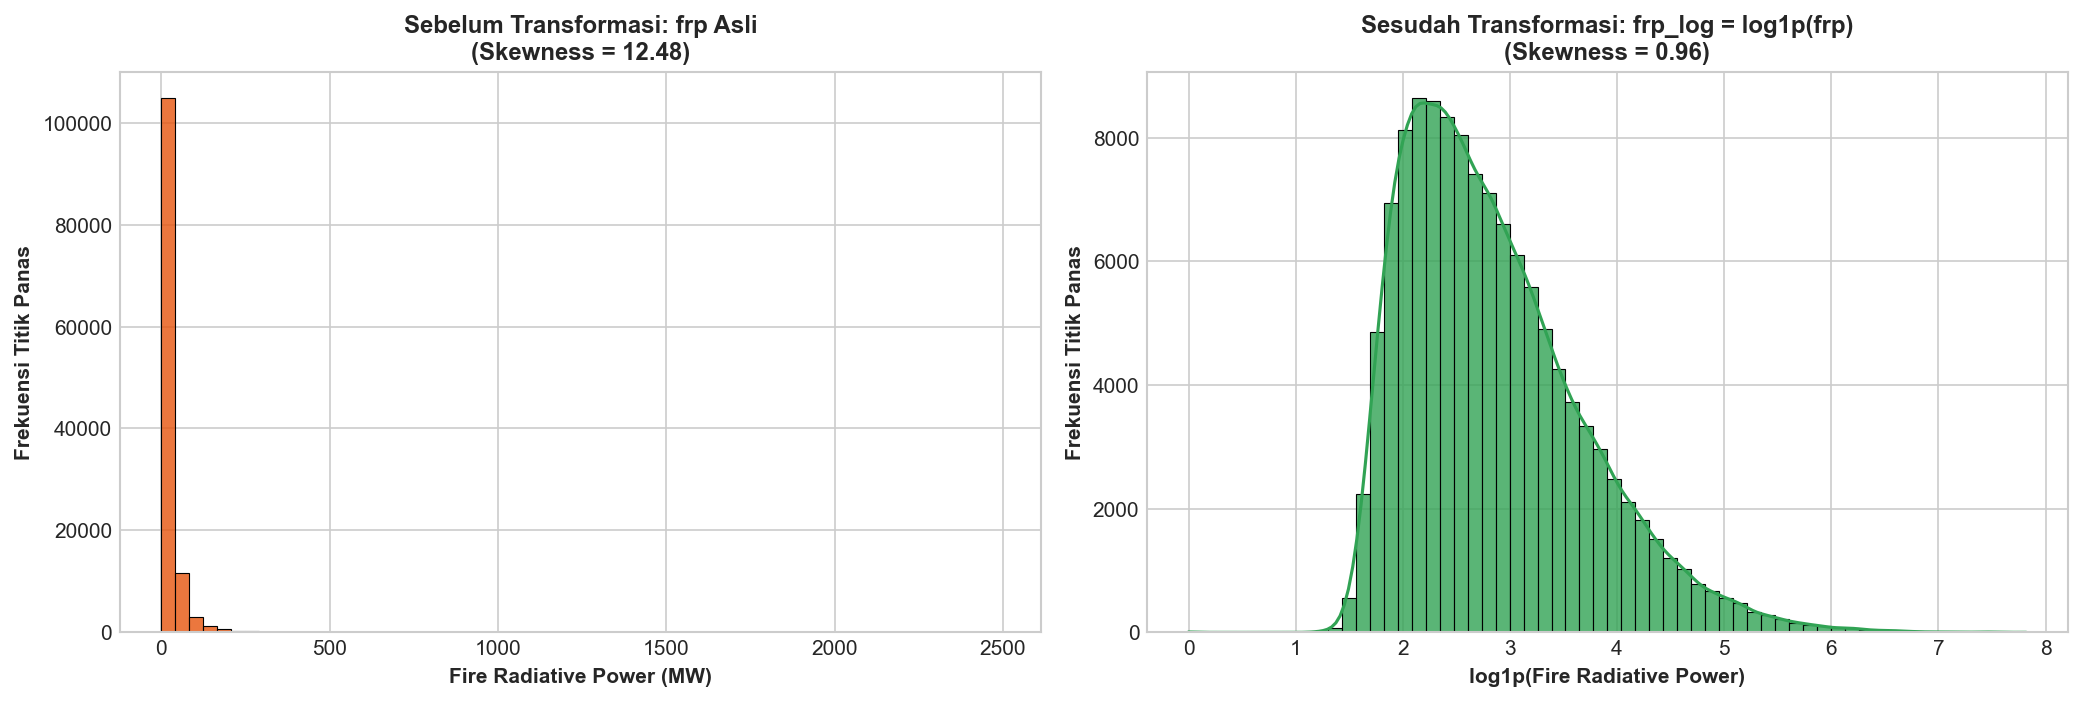

In [16]:
df_prep['frp_log'] = np.log1p(df_prep['frp'])

frp_compare = pd.DataFrame({
    'frp (Asli, MW)': [df_prep['frp'].mean(), df_prep['frp'].median(), df_prep['frp'].std(),
                       df_prep['frp'].skew(), df_prep['frp'].min(), df_prep['frp'].max()],
    'frp_log (log1p)': [df_prep['frp_log'].mean(), df_prep['frp_log'].median(), df_prep['frp_log'].std(),
                        df_prep['frp_log'].skew(), df_prep['frp_log'].min(), df_prep['frp_log'].max()]
}, index=['Mean', 'Median', 'Std', 'Skewness', 'Min', 'Max']).round(4)
display(frp_compare)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.histplot(df_prep['frp'], bins=60, color='#e6550d', alpha=0.8, ax=axes[0])
axes[0].set_title(f"Sebelum Transformasi: frp Asli\n(Skewness = {df_prep['frp'].skew():.2f})", fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Fire Radiative Power (MW)', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Frekuensi Titik Panas', fontsize=10, fontweight='bold')

sns.histplot(df_prep['frp_log'], bins=60, kde=True, color='#31a354', alpha=0.8, ax=axes[1])
axes[1].set_title(f"Sesudah Transformasi: frp_log = log1p(frp)\n(Skewness = {df_prep['frp_log'].skew():.2f})", fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('log1p(Fire Radiative Power)', fontsize=10, fontweight='bold')
axes[1].set_ylabel('Frekuensi Titik Panas', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

#### **Penjelasan dan Interpretasi Transformasi Logaritmik (4.2)**
1. **Sebelum transformasi (panel kiri)**: `frp` asli sangat menceng kanan dengan **skewness = 12,48**. Hampir seluruh observasi menumpuk di dekat nol, sementara ekor kanan memanjang hingga **2.488,53 MW**. Selisih *mean* (**26,37 MW**) dan *median* (**13,74 MW**) yang besar serta *std* **48,34 MW** menunjukkan distribusi yang didominasi nilai ekstrem.
2. **Sesudah transformasi (panel kanan)**: `frp_log` membentuk distribusi menyerupai lonceng dengan **skewness turun drastis menjadi 0,96** (berkurang ±92%). *Mean* (**2,85**) dan *median* (**2,69**) kini berdekatan, dan rentang nilai menyempit menjadi **0 – 7,82**.
3. **Implikasi**: Seluruh 11.932 titik kebakaran ekstrem tetap tersimpan, tetapi pengaruhnya tidak lagi mendominasi perhitungan jarak atau gradien model. Selanjutnya, `frp_log` digunakan sebagai fitur prediktor menggantikan `frp` asli.

### **4.3 Encoding Variabel Kategorikal**
- **Encoding biner fitur prediktor**: `satellite` → `satellite_enc` (`Aqua` = 1, `Terra` = 0) dan `daynight` → `daynight_enc` (`N` = 1, `D` = 0). Karena masing-masing hanya memiliki dua kategori, *binary encoding* cukup tanpa menambah dimensi seperti *one-hot encoding*.
- **Ordinal encoding target**: `conf_cat` → `target_class` (`Low (<30%)` = 0, `Nominal (30%–79%)` = 1, `High (80%–100%)` = 2). Urutan angka mencerminkan tingkatan prioritas verifikasi yang semakin tinggi.

Sel berikut melakukan ketiga *encoding* tersebut dan menampilkan tabel pemetaan nilai asli ke nilai hasil *encoding* beserta jumlah barisnya.

In [17]:
df_prep['satellite_enc'] = df_prep['satellite'].map({'Aqua': 1, 'Terra': 0})
df_prep['daynight_enc'] = df_prep['daynight'].map({'N': 1, 'D': 0})

target_map = {'Low (<30%)': 0, 'Nominal (30%–79%)': 1, 'High (80%–100%)': 2}
df_prep['target_class'] = df_prep['conf_cat'].map(target_map).astype(int)

for source_col, encoded_col in [('satellite', 'satellite_enc'), ('daynight', 'daynight_enc'), ('conf_cat', 'target_class')]:
    mapping_table = df_prep.groupby([source_col, encoded_col], observed=True).size().rename('Jumlah Baris').reset_index()
    display(mapping_table)

print(f"Jumlah nilai kosong hasil encoding : {df_prep[['satellite_enc', 'daynight_enc', 'target_class']].isnull().sum().sum()}")

,satellite,satellite_enc,Jumlah Baris
0,Aqua,1,72265
1,Terra,0,50344


,daynight,daynight_enc,Jumlah Baris
0,D,0,69082
1,N,1,53527


,conf_cat,target_class,Jumlah Baris
0,Low (<30%),0,7198
1,Nominal (30%–79%),1,76021
2,High (80%–100%),2,39390


Jumlah nilai kosong hasil encoding : 0

#### **Interpretasi Encoding (4.3)**
Seluruh nilai kategorikal berhasil dipetakan tanpa menghasilkan nilai kosong (**0 `NaN`**), yang berarti tidak ada kategori di luar kamus pemetaan. Hasil pemetaan konsisten dengan temuan EDA: `satellite_enc` = 1 (**Aqua**) sebanyak **72.265 baris** dan = 0 (**Terra**) sebanyak **50.344 baris**; `daynight_enc` = 0 (**Siang**) sebanyak **69.082 baris** dan = 1 (**Malam**) sebanyak **53.527 baris**; sedangkan `target_class` = 0 / 1 / 2 masing-masing berjumlah **7.198 / 76.021 / 39.390 baris** (*Low / Nominal / High*).

### **4.4 Pembagian Data (*Stratified Train-Test Split*)**
Fitur prediktor `X` terdiri atas 10 kolom: `latitude`, `longitude`, `brightness`, `bright_t31`, `delta_temp`, `frp_log`, `scan`, `acq_hour`, `satellite_enc`, dan `daynight_enc`, sedangkan target `y` adalah `target_class`. Data dibagi dengan rasio **80 : 20** menggunakan `train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)`. Parameter `stratify=y` wajib digunakan karena EDA 2.4.1 menunjukkan *class imbalance* (kelas *Low* hanya 5,87%), sehingga proporsi ketiga kelas harus identik di data latih dan data uji.

Sel berikut melakukan pembagian data, lalu menampilkan ukuran tiap partisi dan tabel perbandingan distribusi kelas.

In [18]:
from sklearn.model_selection import train_test_split

feature_cols = ['latitude', 'longitude', 'brightness', 'bright_t31', 'delta_temp',
                'frp_log', 'scan', 'acq_hour', 'satellite_enc', 'daynight_enc']
X = df_prep[feature_cols]
y = df_prep['target_class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X       : {X.shape[0]:,} baris x {X.shape[1]} fitur")
print(f"X_train : {X_train.shape[0]:,} baris x {X_train.shape[1]} fitur | y_train : {y_train.shape[0]:,}")
print(f"X_test  : {X_test.shape[0]:,} baris x {X_test.shape[1]} fitur | y_test  : {y_test.shape[0]:,}")

class_names = {0: 'Low (<30%)', 1: 'Nominal (30%–79%)', 2: 'High (80%–100%)'}
split_dist = pd.DataFrame({
    'Keseluruhan (n)': y.value_counts().sort_index(),
    'Keseluruhan (%)': (y.value_counts(normalize=True).sort_index() * 100).round(2),
    'Train (n)': y_train.value_counts().sort_index(),
    'Train (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Test (n)': y_test.value_counts().sort_index(),
    'Test (%)': (y_test.value_counts(normalize=True).sort_index() * 100).round(2)
})
split_dist.index = [f"{i} - {class_names[i]}" for i in split_dist.index]
split_dist.index.name = 'target_class'
display(split_dist)

X       : 122,609 baris x 10 fitur
X_train : 98,087 baris x 10 fitur | y_train : 98,087
X_test  : 24,522 baris x 10 fitur | y_test  : 24,522

,Keseluruhan (n),Keseluruhan (%),Train (n),Train (%),Test (n),Test (%)
target_class,,,,,,
0 - Low (<30%),7198,5.8700,5758,5.8700,1440,5.8700
1 - Nominal (30%–79%),76021,62.00,60817,62.00,15204,62.00
2 - High (80%–100%),39390,32.13,31512,32.13,7878,32.13


#### **Interpretasi Stratified Split (4.4)**
Pembagian menghasilkan **`X_train` = 98.087 baris** dan **`X_test` = 24.522 baris** dengan 10 fitur. Proporsi kelas pada kedua partisi **identik dengan populasi**: *Nominal* **62,00%** (60.817 latih / 15.204 uji), *High* **32,13%** (31.512 / 7.878), dan *Low* **5,87%** (5.758 / 1.440). Dengan demikian, kelas minoritas *Low* tetap terwakili di data uji sebanyak 1.440 baris, sehingga evaluasi Macro F1-Score dan Recall kelas *High* nantinya valid dan tidak bias akibat pembagian acak.

### **4.5 Feature Scaling (`RobustScaler`)**
`RobustScaler` dipilih karena menskalakan data menggunakan **median** dan **IQR** dengan rumus $x' = \dfrac{x - \text{median}}{Q_3 - Q_1}$, sehingga tahan terhadap *outlier* suhu dan radiasi api yang sengaja dipertahankan pada tahap *cleaning* (berbeda dengan `StandardScaler` yang menggunakan *mean* dan *std* yang mudah terdistorsi nilai ekstrem). Penskalaan diterapkan pada 8 fitur numerik kontinu (`latitude`, `longitude`, `brightness`, `bright_t31`, `delta_temp`, `frp_log`, `scan`, `acq_hour`), sedangkan fitur biner `satellite_enc` dan `daynight_enc` dibiarkan tetap 0/1.

Untuk mencegah *data leakage*, `fit_transform` **hanya** dilakukan pada `X_train`, lalu parameter yang sama digunakan untuk `transform` pada `X_test`. Sel berikut menampilkan parameter *scaler*, perbandingan `X_train.head()`, serta ringkasan statistik `describe()` **sebelum dan sesudah** *scaling*.

In [19]:
from sklearn.preprocessing import RobustScaler

num_features = ['latitude', 'longitude', 'brightness', 'bright_t31', 'delta_temp', 'frp_log', 'scan', 'acq_hour']

scaler = RobustScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_features] = scaler.fit_transform(X_train[num_features])
X_test_scaled[num_features] = scaler.transform(X_test[num_features])

scaler_params = pd.DataFrame({'Median (center_)': scaler.center_, 'IQR (scale_)': scaler.scale_}, index=num_features).round(4)
print("=== PARAMETER ROBUSTSCALER (DIPELAJARI DARI X_train) ===")
display(scaler_params)

print("=== X_train.head() SEBELUM SCALING ===")
display(X_train.head())
print("=== X_train.head() SESUDAH SCALING (RobustScaler) ===")
display(X_train_scaled.head())

describe_cols = ['mean', '50%', 'std', 'min', 'max']
print("=== RINGKASAN STATISTIK X_train SEBELUM SCALING ===")
display(X_train[num_features].describe().T[describe_cols].round(4))
print("=== RINGKASAN STATISTIK X_train SESUDAH SCALING ===")
display(X_train_scaled[num_features].describe().T[describe_cols].round(4))

print(f"Dimensi akhir siap modeling -> X_train_scaled: {X_train_scaled.shape} | X_test_scaled: {X_test_scaled.shape}")

=== PARAMETER ROBUSTSCALER (DIPELAJARI DARI X_train) ===

,Median (center_),IQR (scale_)
latitude,-2.6508,1.8880
longitude,113.49,9.1436
brightness,315.65,13.70
bright_t31,295.96,5.6100
delta_temp,19.56,12.70
frp_log,2.6892,1.1262
scan,1.1500,0.4400
acq_hour,8.0000,6.0000


=== X_train.head() SEBELUM SCALING ===

,latitude,longitude,brightness,bright_t31,delta_temp,frp_log,scan,acq_hour,satellite_enc,daynight_enc
111503,-2.5272,113.02,323.50,294.10,29.40,3.0620,1.0600,20,1,1
70399,-3.6363,104.67,361.41,304.90,56.51,4.6957,1.1600,13,0,1
72095,-2.6043,121.67,316.89,290.98,25.91,3.4880,1.6800,12,0,1
53541,-8.0498,114.23,306.69,291.96,14.73,3.7216,4.3100,1,0,0
117617,-2.9766,113.30,309.86,295.81,14.05,1.9430,1.0000,13,0,1


=== X_train.head() SESUDAH SCALING (RobustScaler) ===

...

=== RINGKASAN STATISTIK X_train SEBELUM SCALING ===

,mean,50%,std,min,max
latitude,-2.8612,-2.6508,2.5788,-10.84,5.5737
longitude,116.37,113.49,10.80,95.37,140.98
brightness,319.39,315.65,14.81,300.00,505.50
bright_t31,295.73,295.96,5.0606,266.86,342.77
delta_temp,23.65,19.56,13.31,10.00,179.32
frp_log,2.8487,2.6892,0.8398,0.0000,7.8198
scan,1.3909,1.1500,0.5910,1.0000,4.8200
acq_hour,10.08,8.0000,5.0209,0.0000,23.00


=== RINGKASAN STATISTIK X_train SESUDAH SCALING ===

,mean,50%,std,min,max
latitude,-0.1115,0.0000,1.3658,-4.3382,4.3561
longitude,0.3155,0.0000,1.1809,-1.9812,3.0064
brightness,0.2729,0.0000,1.0808,-1.1423,13.86
bright_t31,-0.0401,0.0000,0.9021,-5.1872,8.3440
delta_temp,0.3223,0.0000,1.0479,-0.7528,12.58
frp_log,0.1416,0.0000,0.7457,-2.3879,4.5558
scan,0.5476,0.0000,1.3432,-0.3409,8.3409
acq_hour,0.3459,0.0000,0.8368,-1.3333,2.5000


Dimensi akhir siap modeling -> X_train_scaled: (98087, 10) | X_test_scaled: (24522, 10)

#### **Interpretasi Feature Scaling (4.5)**
1. **Parameter dipelajari hanya dari `X_train`**: Contohnya, `brightness` memiliki median **315,65 K** dan IQR **13,70 K**, `delta_temp` memiliki median **19,56 K** dan IQR **12,70 K**, serta `frp_log` memiliki median **2,69** dan IQR **1,13**. Parameter yang sama diterapkan pada `X_test` sehingga tidak ada informasi data uji yang bocor ke proses pelatihan.
2. **Sebelum vs sesudah scaling**: Sebelum *scaling*, rentang antarfitur sangat timpang (misalnya `longitude` ±95–141, `brightness` 300–505,50 K, sedangkan `scan` hanya 1–4,82 dan `frp_log` 0–7,82). Sesudah *scaling*, **median seluruh fitur numerik tepat bernilai 0** dan *std* berada di kisaran **0,75–1,37**, sehingga semua fitur berada pada skala yang sebanding.
3. **Outlier tetap terjaga**: Nilai ekstrem tidak dipotong. Contohnya, `brightness` maksimum menjadi **13,86** dan `delta_temp` maksimum **12,58** (dalam satuan IQR), sehingga informasi kebakaran berintensitas tinggi tetap tersedia bagi model tanpa mendistorsi skala data mayoritas. Fitur biner `satellite_enc` dan `daynight_enc` tetap bernilai 0/1.
4. **Output akhir**: `X_train_scaled` berukuran **(98.087, 10)** dan `X_test_scaled` berukuran **(24.522, 10)**.

---
### **Ringkasan Akhir Tahap 1–4**
| Tahap | Hasil Utama |
|---|---|
| **1. Business Understanding** | Masalah prioritas verifikasi *hotspot* dirumuskan menjadi klasifikasi 3 kelas dengan target Macro F1 ≥ 0,70 dan Recall *High* ≥ 0,75 |
| **2. Data Gathering & EDA** | `df_all` 122.609 × 15; ditemukan *class imbalance*, anomali *nocturnal hotspot*, lonjakan musiman, distribusi *right-skewed*, dan multikolinearitas `scan`–`track` |
| **3. Data Cleaning** | 8 kolom di-drop (`type`, `instrument`, `version`, `track`, `acq_date`, `acq_date_dt`, `year_month`, `confidence`); 0 baris dihapus; `df_clean` 122.609 × 10 tanpa *missing value* |
| **4. Preprocessing** | Fitur baru `delta_temp`, `acq_hour`, `frp_log`; *encoding* biner & ordinal; *stratified split* 98.087 / 24.522 baris; `RobustScaler` pada 8 fitur numerik |

Variabel `X_train_scaled`, `X_test_scaled`, `y_train`, dan `y_test` siap digunakan pada tahap pemodelan (*Modeling*) dan evaluasi berikutnya.